In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected yet.")

PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4


In [ ]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("Environment check")
print("-----------------")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Environment check
-----------------
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
NumPy: 2.4.6
Scikit-learn: 1.6.1
GPU available: True
GPU: Tesla T4


In [ ]:
import torchvision
import torchvision.transforms as transforms

# Convert images into PyTorch tensors
transform = transforms.ToTensor()

# Download training dataset
train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Download testing dataset
test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)
print("Number of classes:", len(train_dataset.classes))
print("Classes:", train_dataset.classes)

100%|██████████| 170M/170M [25:00<00:00, 114kB/s]


Training images: 50000
Testing images: 10000
Image shape: torch.Size([3, 32, 32])
Number of classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


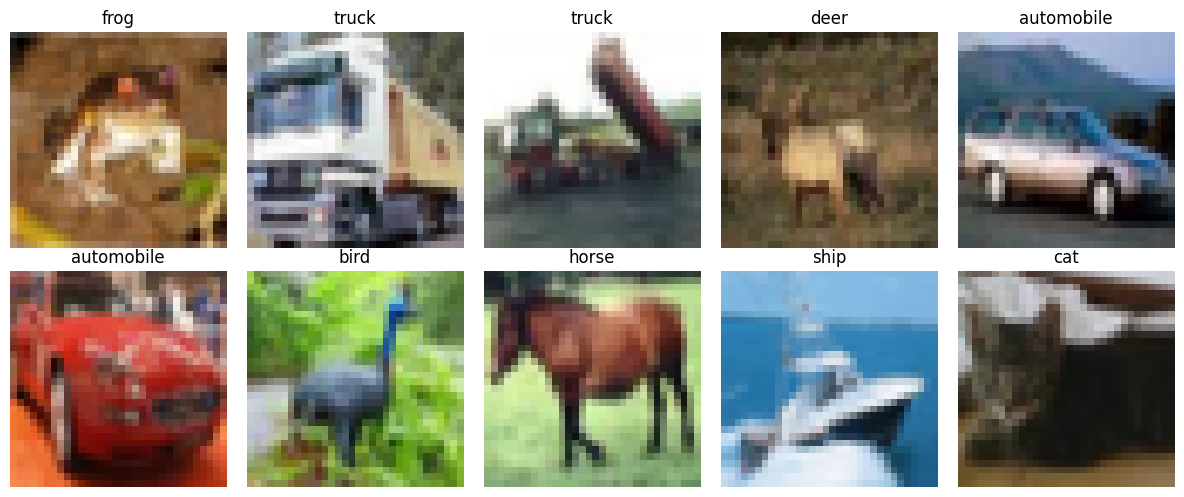

In [ ]:
import matplotlib.pyplot as plt

# Display 10 images
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    # Convert PyTorch tensor to image format
    image = image.permute(1, 2, 0)

    ax.imshow(image)
    ax.set_title(train_dataset.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
image, label = train_dataset[0]

print("Image tensor shape:", image.shape)
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())
print("Image class:", train_dataset.classes[label])
print("Total pixel values:", image.numel())

Image tensor shape: torch.Size([3, 32, 32])
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Image class: frog
Total pixel values: 3072


Class distribution:
airplane: 5000
automobile: 5000
bird: 5000
cat: 5000
deer: 5000
dog: 5000
frog: 5000
horse: 5000
ship: 5000
truck: 5000


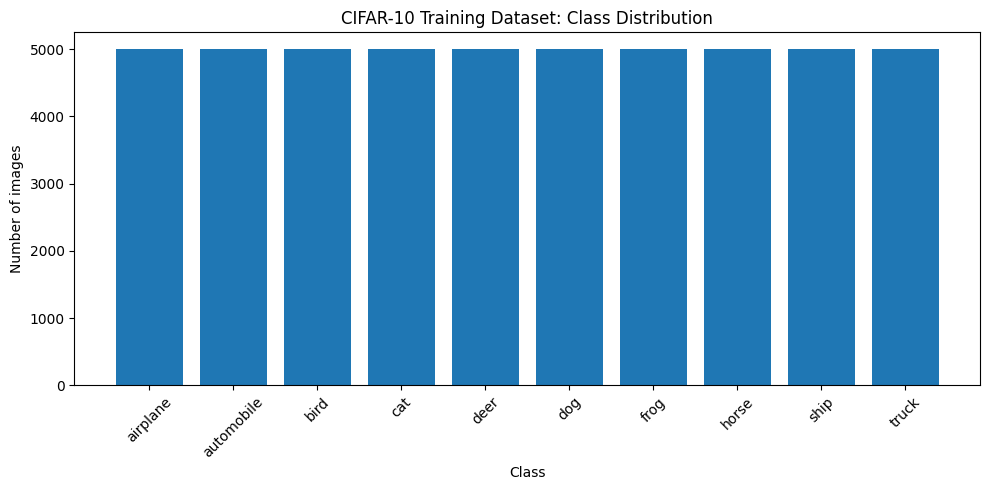

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

class_names = train_dataset.classes
class_counts = np.bincount(train_dataset.targets)

print("Class distribution:")
for name, count in zip(class_names, class_counts):
    print(f"{name}: {count}")

plt.figure(figsize=(10, 5))
plt.bar(class_names, class_counts)
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.title("CIFAR-10 Training Dataset: Class Distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

indices = np.arange(len(train_dataset))
labels = np.array(train_dataset.targets)

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.10,
    random_state=42,
    stratify=labels
)

train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(train_dataset, val_indices)

print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Testing samples:", len(test_dataset))

Training samples: 45000
Validation samples: 5000
Testing samples: 10000


In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 128

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Inspect one training batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Device:", torch.device("cuda" if torch.cuda.is_available() else "cpu"))

Image batch shape: torch.Size([128, 3, 32, 32])
Label batch shape: torch.Size([128])
Device: cuda


In [ ]:
import torch
import torch.nn as nn

class BaselineCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            # First convolution block
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Second convolution block
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# Create the model
model = BaselineCNN()

# Move model to GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print(model)

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [ ]:
# Take one batch of images
images, labels = next(iter(train_loader))

# Move images to GPU
images = images.to(device)

# Put model in evaluation mode
model.eval()

# Make predictions without calculating gradients
with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("Model device:", next(model.parameters()).device)

Input shape: torch.Size([128, 3, 32, 32])
Output shape: torch.Size([128, 10])
Model parameters: 545098
Model device: cuda:0


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random

# Set random seeds for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Reinitialize the model using the fixed seed
model = BaselineCNN().to(device)

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Model ready for training!")
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Loss function: CrossEntropyLoss")
print("Device:", device)

Model ready for training!
Optimizer: Adam
Learning rate: 0.001
Loss function: CrossEntropyLoss
Device: cuda


In [ ]:
from tqdm.auto import tqdm

EPOCHS = 10

train_history = []
val_history = []

def evaluate(model, loader):
    model.eval()

    total = 0
    correct = 0
    total_loss = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100 * correct / total


for epoch in range(EPOCHS):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    progress = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")

    for images, labels in progress:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        progress.set_postfix(loss=loss.item())

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    val_loss, val_accuracy = evaluate(model, val_loader)

    train_history.append(train_accuracy)
    val_history.append(val_accuracy)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_accuracy:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.2f}%")

# Save trained model
torch.save(model.state_dict(), "baseline_cnn.pth")

print("\nTraining completed!")

Epoch 1/10:   0%|          | 0/352 [00:00<?, ?it/s]


Epoch 1/10
Training Loss: 1.6550
Training Accuracy: 39.48%
Validation Loss: 1.3278
Validation Accuracy: 51.38%


Epoch 2/10:   0%|          | 0/352 [00:00<?, ?it/s]


Epoch 2/10
Training Loss: 1.3284
Training Accuracy: 52.13%
Validation Loss: 1.2027
Validation Accuracy: 56.54%


Epoch 3/10:   0%|          | 0/352 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f982d828900>
Traceback (most recent call last):
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f982d828900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only test a child process'
self._shutdown_workers()AssertionError
:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
can only test a child process    
if w.is_alive():
  File "/usr/lib/

... (14 outputs left out)


Epoch 9/10
Training Loss: 0.8423
Training Accuracy: 69.94%
Validation Loss: 0.8805
Validation Accuracy: 69.14%


Epoch 10/10:   0%|          | 0/352 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f982d828900><function _MultiProcessingDataLoaderIter.__del__ at 0x7f982d828900>

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    self._shutdown_workers()    
if w.is_alive():  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

    if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
assert self._parent_pid == os.getpid(), 'can only test a


Epoch 10/10
Training Loss: 0.8082
Training Accuracy: 71.17%
Validation Loss: 0.8706
Validation Accuracy: 69.46%

Training completed!


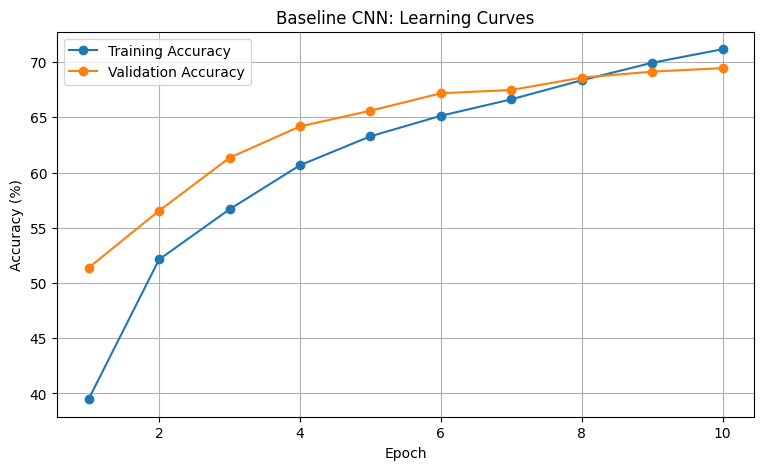

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(9, 5))

plt.plot(epochs, train_history, marker="o", label="Training Accuracy")
plt.plot(epochs, val_history, marker="o", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Baseline CNN: Learning Curves")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_subset,
    batch_size=128,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("DataLoaders recreated successfully!")

DataLoaders recreated successfully!


In [ ]:
test_loss, test_accuracy = evaluate(model, test_loader)

print("BASELINE CNN TEST RESULTS")
print("-------------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")

BASELINE CNN TEST RESULTS
-------------------------
Test Loss: 0.8809
Test Accuracy: 69.45%


In [ ]:
import torch
import torch.nn.functional as F
import numpy as np

model.eval()

all_logits = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)

        all_logits.append(outputs.cpu())
        all_labels.append(labels)

test_logits = torch.cat(all_logits)
test_labels = torch.cat(all_labels)

# Convert raw scores into probabilities
test_probs = F.softmax(test_logits, dim=1)

# Find predicted classes
predictions = test_probs.argmax(dim=1)

# Maximum probability = model confidence
confidences = test_probs.max(dim=1).values

# Identify correct and incorrect predictions
correct_predictions = predictions == test_labels

print("Number of predictions:", len(predictions))
print("Average confidence:", confidences.mean().item())
print("Average confidence on correct predictions:",
      confidences[correct_predictions].mean().item())
print("Average confidence on incorrect predictions:",
      confidences[~correct_predictions].mean().item())

Number of predictions: 10000
Average confidence: 0.7016503214836121
Average confidence on correct predictions: 0.7724819779396057
Average confidence on incorrect predictions: 0.5406270623207092


In [ ]:
import torch.nn.functional as F

def calculate_ece(probs, labels, n_bins=15):

    confidences, predictions = probs.max(dim=1)
    accuracies = predictions.eq(labels)

    bin_boundaries = torch.linspace(0, 1, n_bins + 1)
    ece = torch.tensor(0.0)

    for i in range(n_bins):

        lower = bin_boundaries[i]
        upper = bin_boundaries[i + 1]

        if i == 0:
            mask = (confidences >= lower) & (confidences <= upper)
        else:
            mask = (confidences > lower) & (confidences <= upper)

        if mask.sum() > 0:
            bin_accuracy = accuracies[mask].float().mean()
            bin_confidence = confidences[mask].mean()

            ece += mask.float().mean() * torch.abs(
                bin_accuracy - bin_confidence
            )

    return ece.item()


# Negative log-likelihood
nll = F.cross_entropy(test_logits, test_labels).item()

# Multiclass Brier score
one_hot = F.one_hot(test_labels, num_classes=10).float()
brier = torch.mean(torch.sum((test_probs - one_hot) ** 2, dim=1)).item()

# Expected calibration error
ece = calculate_ece(test_probs, test_labels)

print("BASELINE CALIBRATION RESULTS")
print("----------------------------")
print(f"ECE: {ece:.4f}")
print(f"NLL: {nll:.4f}")
print(f"Brier Score: {brier:.4f}")

BASELINE CALIBRATION RESULTS
----------------------------
ECE: 0.0098
NLL: 0.8809
Brier Score: 0.4178


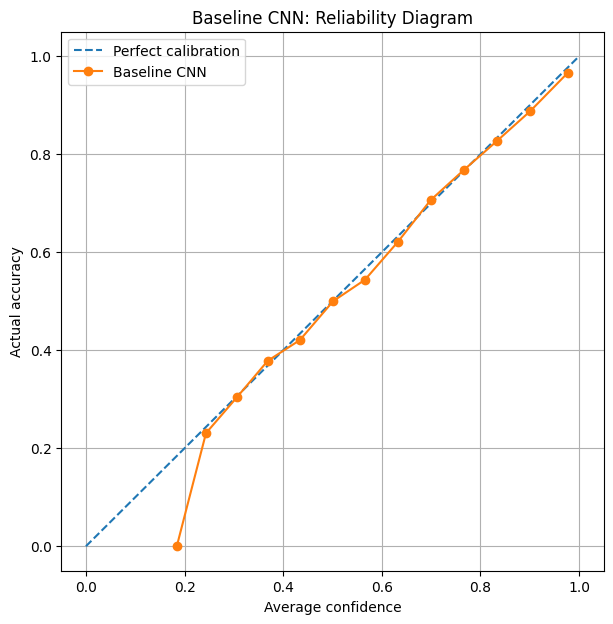

In [ ]:
import matplotlib.pyplot as plt

def plot_reliability(probs, labels, n_bins=15):

    confidences, predictions = probs.max(dim=1)
    accuracies = predictions.eq(labels).float()

    boundaries = torch.linspace(0, 1, n_bins + 1)

    bin_conf = []
    bin_acc = []

    for i in range(n_bins):
        mask = (
            (confidences >= boundaries[i]) &
            (confidences < boundaries[i + 1])
        )

        if mask.sum() > 0:
            bin_conf.append(confidences[mask].mean().item())
            bin_acc.append(accuracies[mask].mean().item())

    plt.figure(figsize=(7, 7))

    plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")
    plt.plot(bin_conf, bin_acc, "o-", label="Baseline CNN")

    plt.xlabel("Average confidence")
    plt.ylabel("Actual accuracy")
    plt.title("Baseline CNN: Reliability Diagram")
    plt.legend()
    plt.grid(True)
    plt.show()


plot_reliability(test_probs, test_labels)

In [ ]:
import torch
import torch.nn.functional as F

# Collect validation predictions
model.eval()

val_logits_list = []
val_labels_list = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)

        val_logits_list.append(outputs.cpu())
        val_labels_list.append(labels)

val_logits = torch.cat(val_logits_list).to(device)
val_labels = torch.cat(val_labels_list).to(device)

# Learn one temperature parameter
log_temperature = torch.nn.Parameter(
    torch.zeros(1, device=device)
)

temperature_optimizer = torch.optim.LBFGS(
    [log_temperature],
    lr=0.01,
    max_iter=100
)

def temperature_closure():
    temperature_optimizer.zero_grad()

    temperature = torch.exp(log_temperature)

    loss = F.cross_entropy(
        val_logits / temperature,
        val_labels
    )

    loss.backward()
    return loss

# Optimize temperature on validation data
temperature_optimizer.step(temperature_closure)

optimal_temperature = torch.exp(log_temperature).item()

print("Optimal temperature:", optimal_temperature)
print("Validation samples used:", len(val_labels))

Optimal temperature: 1.0535962581634521
Validation samples used: 5000


In [ ]:
# Original validation probabilities
val_probs_before = F.softmax(val_logits, dim=1)

# Calibrated validation probabilities
val_probs_after = F.softmax(
    val_logits / optimal_temperature,
    dim=1
)

print("VALIDATION CALIBRATION COMPARISON")
print("---------------------------------")

print(
    "NLL before:",
    F.cross_entropy(val_logits, val_labels).item()
)

print(
    "NLL after:",
    F.cross_entropy(
        val_logits / optimal_temperature,
        val_labels
    ).item()
)

print(
    "ECE before:",
    calculate_ece(val_probs_before.cpu(), val_labels.cpu())
)

print(
    "ECE after:",
    calculate_ece(val_probs_after.cpu(), val_labels.cpu())
)

VALIDATION CALIBRATION COMPARISON
---------------------------------
NLL before: 0.8706071972846985
NLL after: 0.8683150410652161
ECE before: 0.010196277871727943
ECE after: 0.01112220250070095


In [ ]:
# Apply validation-fitted temperature to test logits
calibrated_test_probs = F.softmax(
    test_logits / optimal_temperature,
    dim=1
)

calibrated_nll = F.cross_entropy(
    test_logits / optimal_temperature,
    test_labels
).item()

calibrated_ece = calculate_ece(
    calibrated_test_probs,
    test_labels
)

one_hot = F.one_hot(
    test_labels,
    num_classes=10
).float()

calibrated_brier = torch.mean(
    torch.sum(
        (calibrated_test_probs - one_hot) ** 2,
        dim=1
    )
).item()

calibrated_accuracy = (
    calibrated_test_probs.argmax(dim=1) == test_labels
).float().mean().item() * 100

print("TEMPERATURE-SCALED TEST RESULTS")
print("--------------------------------")
print(f"Temperature: {optimal_temperature:.4f}")
print(f"Accuracy: {calibrated_accuracy:.2f}%")
print(f"NLL: {calibrated_nll:.4f}")
print(f"ECE: {calibrated_ece:.4f}")
print(f"Brier Score: {calibrated_brier:.4f}")

TEMPERATURE-SCALED TEST RESULTS
--------------------------------
Temperature: 1.0536
Accuracy: 69.45%
NLL: 0.8782
ECE: 0.0129
Brier Score: 0.4178


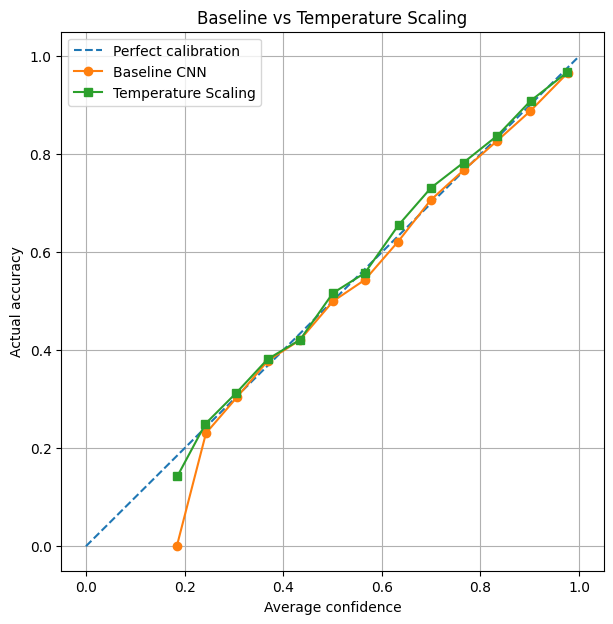

In [ ]:
import matplotlib.pyplot as plt
import torch

def get_reliability_points(probs, labels, n_bins=15):
    confidences, predictions = probs.max(dim=1)
    accuracies = predictions.eq(labels).float()

    boundaries = torch.linspace(0, 1, n_bins + 1)
    bin_conf, bin_acc = [], []

    for i in range(n_bins):
        mask = (
            (confidences >= boundaries[i]) &
            (confidences < boundaries[i + 1])
        )

        if mask.sum() > 0:
            bin_conf.append(confidences[mask].mean().item())
            bin_acc.append(accuracies[mask].mean().item())

    return bin_conf, bin_acc


# Original and calibrated test probabilities
baseline_conf, baseline_acc = get_reliability_points(
    test_probs, test_labels
)

scaled_conf, scaled_acc = get_reliability_points(
    calibrated_test_probs, test_labels
)

plt.figure(figsize=(7, 7))

plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")
plt.plot(baseline_conf, baseline_acc, "o-", label="Baseline CNN")
plt.plot(scaled_conf, scaled_acc, "s-", label="Temperature Scaling")

plt.xlabel("Average confidence")
plt.ylabel("Actual accuracy")
plt.title("Baseline vs Temperature Scaling")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import torch.nn as nn

def enable_dropout(model):
    model.eval()

    for module in model.modules():
        if isinstance(module, nn.Dropout):
            module.train()

In [ ]:
import torch
import torch.nn.functional as F
import numpy as np

def mc_dropout_predict(model, loader, passes=20):

    enable_dropout(model)

    all_mean_probs = []
    all_predictive_entropy = []
    all_expected_entropy = []
    all_mutual_information = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            # Store predictions from repeated passes
            pass_probs = []

            for _ in range(passes):
                outputs = model(images)
                probabilities = F.softmax(outputs, dim=1)
                pass_probs.append(probabilities)

            # Shape: [passes, batch_size, 10]
            pass_probs = torch.stack(pass_probs)

            # Average prediction probabilities
            mean_probs = pass_probs.mean(dim=0)

            # Predictive entropy
            predictive_entropy = -torch.sum(
                mean_probs * torch.log(mean_probs + 1e-10),
                dim=1
            )

            # Expected entropy
            individual_entropy = -torch.sum(
                pass_probs * torch.log(pass_probs + 1e-10),
                dim=2
            )

            expected_entropy = individual_entropy.mean(dim=0)

            # Mutual information
            mutual_information = (
                predictive_entropy - expected_entropy
            )

            all_mean_probs.append(mean_probs.cpu())
            all_predictive_entropy.append(predictive_entropy.cpu())
            all_expected_entropy.append(expected_entropy.cpu())
            all_mutual_information.append(mutual_information.cpu())
            all_labels.append(labels)

    model.eval()

    return {
        "probabilities": torch.cat(all_mean_probs),
        "predictive_entropy": torch.cat(all_predictive_entropy),
        "expected_entropy": torch.cat(all_expected_entropy),
        "mutual_information": torch.cat(all_mutual_information),
        "labels": torch.cat(all_labels)
    }


mc_val = mc_dropout_predict(
    model,
    val_loader,
    passes=20
)

print("MC Dropout predictions generated!")
print("Number of images:", len(mc_val["labels"]))
print("Number of passes:", 20)
print("Probability shape:", mc_val["probabilities"].shape)

MC Dropout predictions generated!
Number of images: 5000
Number of passes: 20
Probability shape: torch.Size([5000, 10])


In [ ]:
import torch
import torch.nn.functional as F

mc_probs = mc_val["probabilities"]
mc_labels = mc_val["labels"]

# Predictions
mc_predictions = mc_probs.argmax(dim=1)

# Accuracy
mc_accuracy = (
    mc_predictions == mc_labels
).float().mean().item() * 100

# Confidence
mc_confidences = mc_probs.max(dim=1).values
mc_correct = mc_predictions == mc_labels

# NLL
mc_nll = F.nll_loss(
    torch.log(mc_probs + 1e-10),
    mc_labels
).item()

# Brier Score
mc_one_hot = F.one_hot(
    mc_labels,
    num_classes=10
).float()

mc_brier = torch.mean(
    torch.sum((mc_probs - mc_one_hot) ** 2, dim=1)
).item()

# ECE
mc_ece = calculate_ece(mc_probs, mc_labels)

print("MONTE CARLO DROPOUT VALIDATION RESULTS")
print("--------------------------------------")
print(f"Accuracy: {mc_accuracy:.2f}%")
print(f"ECE: {mc_ece:.4f}")
print(f"NLL: {mc_nll:.4f}")
print(f"Brier Score: {mc_brier:.4f}")

print("\nCONFIDENCE ANALYSIS")
print("--------------------------------------")
print(f"Average confidence: {mc_confidences.mean().item():.4f}")
print(f"Confidence on correct predictions: "
      f"{mc_confidences[mc_correct].mean().item():.4f}")
print(f"Confidence on incorrect predictions: "
      f"{mc_confidences[~mc_correct].mean().item():.4f}")

print("\nUNCERTAINTY ANALYSIS")
print("--------------------------------------")
print(f"Predictive entropy: "
      f"{mc_val['predictive_entropy'].mean().item():.4f}")
print(f"Expected entropy: "
      f"{mc_val['expected_entropy'].mean().item():.4f}")
print(f"Mutual information: "
      f"{mc_val['mutual_information'].mean().item():.4f}")

MONTE CARLO DROPOUT VALIDATION RESULTS
--------------------------------------
Accuracy: 69.62%
ECE: 0.0387
NLL: 0.8766
Brier Score: 0.4181

CONFIDENCE ANALYSIS
--------------------------------------
Average confidence: 0.6605
Confidence on correct predictions: 0.7292
Confidence on incorrect predictions: 0.5032

UNCERTAINTY ANALYSIS
--------------------------------------
Predictive entropy: 0.9527
Expected entropy: 0.8373
Mutual information: 0.1154


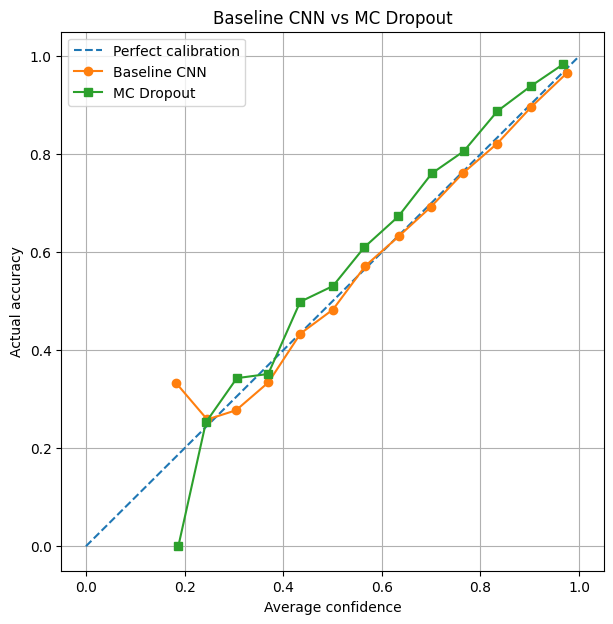

In [ ]:
import matplotlib.pyplot as plt

# Original baseline validation probabilities
baseline_val_probs = val_probs_before.cpu()
baseline_val_labels = val_labels.cpu()

mc_conf, mc_acc = get_reliability_points(
    mc_probs, mc_labels
)

base_conf, base_acc = get_reliability_points(
    baseline_val_probs, baseline_val_labels
)

plt.figure(figsize=(7, 7))

plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")
plt.plot(base_conf, base_acc, "o-", label="Baseline CNN")
plt.plot(mc_conf, mc_acc, "s-", label="MC Dropout")

plt.xlabel("Average confidence")
plt.ylabel("Actual accuracy")
plt.title("Baseline CNN vs MC Dropout")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score
import numpy as np
import torch

# 1 means the prediction is incorrect
baseline_errors = (
    baseline_val_probs.argmax(dim=1) != baseline_val_labels
).numpy()

mc_errors = (
    mc_predictions != mc_labels
).numpy()

# Baseline uncertainty
baseline_uncertainty = (
    1 - baseline_val_probs.max(dim=1).values
).numpy()

# MC Dropout uncertainty
mc_confidence_uncertainty = (
    1 - mc_probs.max(dim=1).values
).numpy()

mc_predictive_entropy = (
    mc_val["predictive_entropy"].numpy()
)

mc_mutual_information = (
    mc_val["mutual_information"].numpy()
)

# Calculate AUROC
results = {
    "Baseline confidence": roc_auc_score(
        baseline_errors,
        baseline_uncertainty
    ),

    "MC Dropout confidence": roc_auc_score(
        mc_errors,
        mc_confidence_uncertainty
    ),

    "MC Dropout predictive entropy": roc_auc_score(
        mc_errors,
        mc_predictive_entropy
    ),

    "MC Dropout mutual information": roc_auc_score(
        mc_errors,
        mc_mutual_information
    )
}

print("ERROR DETECTION AUROC")
print("---------------------")

for method, score in results.items():
    print(f"{method}: {score:.4f}")

ERROR DETECTION AUROC
---------------------
Baseline confidence: 0.8032
MC Dropout confidence: 0.7991
MC Dropout predictive entropy: 0.7858
MC Dropout mutual information: 0.6679


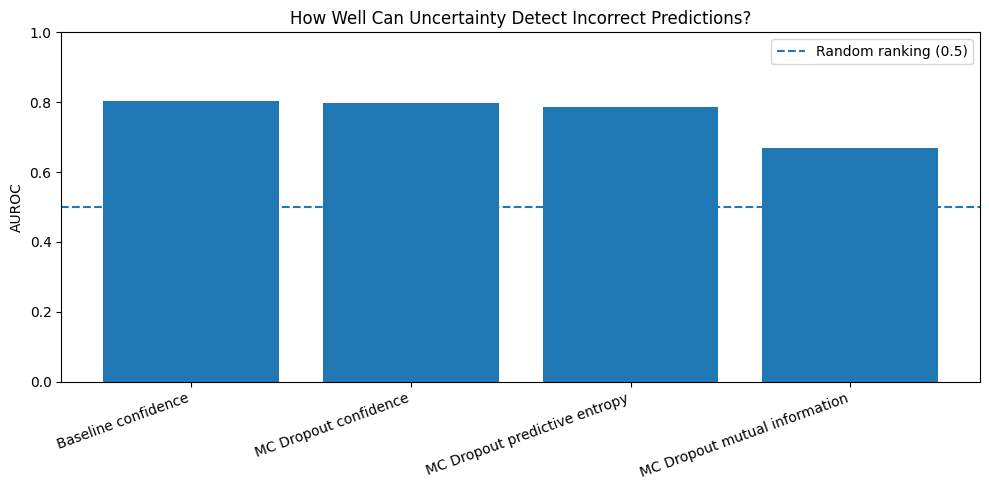

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    list(results.keys()),
    list(results.values())
)

plt.axhline(
    0.5,
    linestyle="--",
    label="Random ranking (0.5)"
)

plt.ylabel("AUROC")
plt.title("How Well Can Uncertainty Detect Incorrect Predictions?")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

ENSEMBLE_SEEDS = [42, 123, 2026]
ensemble_models = []

for seed in ENSEMBLE_SEEDS:

    print(f"\nTraining ensemble model with seed {seed}")

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # Create an independent CNN
    ensemble_model = BaselineCNN().to(device)

    ensemble_optimizer = optim.Adam(
        ensemble_model.parameters(),
        lr=0.001
    )

    ensemble_criterion = nn.CrossEntropyLoss()

    for epoch in range(10):

        ensemble_model.train()

        total_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            ensemble_optimizer.zero_grad()

            outputs = ensemble_model(images)
            loss = ensemble_criterion(outputs, labels)

            loss.backward()
            ensemble_optimizer.step()

            total_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        train_accuracy = 100 * correct / total

        val_loss, val_accuracy = evaluate(
            ensemble_model,
            val_loader
        )

        print(
            f"Seed {seed} | Epoch {epoch+1}/10 | "
            f"Train: {train_accuracy:.2f}% | "
            f"Validation: {val_accuracy:.2f}%"
        )

    # Save each independently trained model
    torch.save(
        ensemble_model.state_dict(),
        f"ensemble_model_seed_{seed}.pth"
    )

    ensemble_models.append(ensemble_model)

    print(f"Model with seed {seed} saved!")

print("\nAll three ensemble models trained successfully!")


Training ensemble model with seed 42
Seed 42 | Epoch 1/10 | Train: 40.49% | Validation: 52.22%
Seed 42 | Epoch 2/10 | Train: 52.90% | Validation: 58.76%
Seed 42 | Epoch 3/10 | Train: 57.92% | Validation: 62.58%
Seed 42 | Epoch 4/10 | Train: 61.28% | Validation: 66.30%
Seed 42 | Epoch 5/10 | Train: 64.62% | Validation: 66.88%
Seed 42 | Epoch 6/10 | Train: 66.59% | Validation: 68.34%
Seed 42 | Epoch 7/10 | Train: 68.45% | Validation: 69.62%
Seed 42 | Epoch 8/10 | Train: 70.19% | Validation: 70.20%
Seed 42 | Epoch 9/10 | Train: 71.70% | Validation: 70.84%
Seed 42 | Epoch 10/10 | Train: 73.27% | Validation: 71.10%
Model with seed 42 saved!

Training ensemble model with seed 123
Seed 123 | Epoch 1/10 | Train: 41.01% | Validation: 50.76%
Seed 123 | Epoch 2/10 | Train: 52.81% | Validation: 59.30%
Seed 123 | Epoch 3/10 | Train: 58.30% | Validation: 62.84%
Seed 123 | Epoch 4/10 | Train: 62.01% | Validation: 64.98%
Seed 123 | Epoch 5/10 | Train: 64.39% | Validation: 66.10%
Seed 123 | Epoch 6/10

In [ ]:
import torch
import torch.nn.functional as F

ensemble_predictions = []

# Put all models in evaluation mode
for ensemble_model in ensemble_models:
    ensemble_model.eval()

# Generate predictions on validation data
with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        batch_predictions = []

        for ensemble_model in ensemble_models:
            outputs = ensemble_model(images)

            probabilities = F.softmax(outputs, dim=1)
            batch_predictions.append(probabilities)

        # Shape: [3, batch_size, 10]
        batch_predictions = torch.stack(batch_predictions)

        ensemble_predictions.append(batch_predictions.cpu())

# Combine all batches
# Shape: [3, 5000, 10]
ensemble_predictions = torch.cat(
    ensemble_predictions,
    dim=1
)

# Average the three models' probabilities
ensemble_probs = ensemble_predictions.mean(dim=0)

# Store validation labels
ensemble_labels = val_subset.dataset.targets

# Use the actual labels from the validation subset
ensemble_labels = torch.tensor([
    val_subset.dataset.targets[i]
    for i in val_subset.indices
])

print("Deep Ensemble predictions generated!")
print("Individual model predictions:", ensemble_predictions.shape)
print("Average ensemble predictions:", ensemble_probs.shape)
print("Validation labels:", ensemble_labels.shape)

Deep Ensemble predictions generated!
Individual model predictions: torch.Size([3, 5000, 10])
Average ensemble predictions: torch.Size([5000, 10])
Validation labels: torch.Size([5000])


In [ ]:
from sklearn.metrics import roc_auc_score

# Classification predictions
ensemble_predicted_classes = ensemble_probs.argmax(dim=1)

ensemble_correct = (
    ensemble_predicted_classes == ensemble_labels
)

ensemble_accuracy = ensemble_correct.float().mean().item() * 100

# Calibration metrics
ensemble_nll = F.nll_loss(
    torch.log(ensemble_probs + 1e-10),
    ensemble_labels
).item()

ensemble_ece = calculate_ece(
    ensemble_probs,
    ensemble_labels
)

ensemble_one_hot = F.one_hot(
    ensemble_labels,
    num_classes=10
).float()

ensemble_brier = torch.mean(
    torch.sum(
        (ensemble_probs - ensemble_one_hot) ** 2,
        dim=1
    )
).item()

# Confidence
ensemble_confidence = ensemble_probs.max(dim=1).values

# Entropy of the averaged predictions
ensemble_entropy = -torch.sum(
    ensemble_probs * torch.log(ensemble_probs + 1e-10),
    dim=1
)

# Average entropy of individual models
individual_entropies = -torch.sum(
    ensemble_predictions *
    torch.log(ensemble_predictions + 1e-10),
    dim=2
)

expected_ensemble_entropy = individual_entropies.mean(dim=0)

# Mutual information: disagreement between models
ensemble_mutual_information = (
    ensemble_entropy - expected_ensemble_entropy
).clamp(min=0)

print("DEEP ENSEMBLE VALIDATION RESULTS")
print("--------------------------------")
print(f"Accuracy: {ensemble_accuracy:.2f}%")
print(f"ECE: {ensemble_ece:.4f}")
print(f"NLL: {ensemble_nll:.4f}")
print(f"Brier Score: {ensemble_brier:.4f}")

print("\nUNCERTAINTY RESULTS")
print("--------------------------------")
print(f"Average confidence: {ensemble_confidence.mean().item():.4f}")
print(f"Predictive entropy: {ensemble_entropy.mean().item():.4f}")
print(f"Expected entropy: {expected_ensemble_entropy.mean().item():.4f}")
print(f"Mutual information: {ensemble_mutual_information.mean().item():.4f}")

DEEP ENSEMBLE VALIDATION RESULTS
--------------------------------
Accuracy: 73.16%
ECE: 0.0643
NLL: 0.7798
Brier Score: 0.3769

UNCERTAINTY RESULTS
--------------------------------
Average confidence: 0.6673
Predictive entropy: 0.9138
Expected entropy: 0.8479
Mutual information: 0.0659


In [ ]:
# 1 means the ensemble made an incorrect prediction
ensemble_errors = (~ensemble_correct).numpy()

# Uncertainty scores
ensemble_confidence_uncertainty = (
    1 - ensemble_confidence
).numpy()

ensemble_entropy_uncertainty = (
    ensemble_entropy
).numpy()

ensemble_mi_uncertainty = (
    ensemble_mutual_information
).numpy()

ensemble_auroc_results = {
    "Ensemble confidence": roc_auc_score(
        ensemble_errors,
        ensemble_confidence_uncertainty
    ),

    "Ensemble predictive entropy": roc_auc_score(
        ensemble_errors,
        ensemble_entropy_uncertainty
    ),

    "Ensemble mutual information": roc_auc_score(
        ensemble_errors,
        ensemble_mi_uncertainty
    )
}

print("DEEP ENSEMBLE ERROR DETECTION")
print("--------------------------------")

for method, score in ensemble_auroc_results.items():
    print(f"{method}: {score:.4f}")

DEEP ENSEMBLE ERROR DETECTION
--------------------------------
Ensemble confidence: 0.8168
Ensemble predictive entropy: 0.7997
Ensemble mutual information: 0.7048


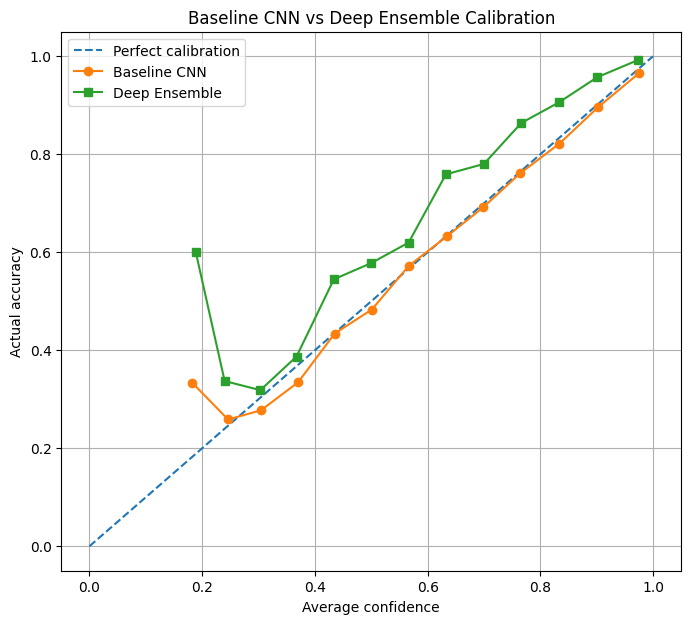

VALIDATION METRIC COMPARISON
--------------------------------
Metric              Baseline     Ensemble
Accuracy              69.46%       73.16%
NLL                   0.8706       0.7798
ECE                   0.0102       0.0643
Brier                 0.4152       0.3769


In [ ]:
# Baseline validation metrics
baseline_val_nll = F.cross_entropy(
    val_logits, val_labels
).item()

baseline_val_ece = calculate_ece(
    baseline_val_probs, baseline_val_labels
)

baseline_val_one_hot = F.one_hot(
    baseline_val_labels,
    num_classes=10
).float()

baseline_val_brier = torch.mean(
    torch.sum(
        (baseline_val_probs - baseline_val_one_hot) ** 2,
        dim=1
    )
).item()

# Reliability points
base_conf, base_acc = get_reliability_points(
    baseline_val_probs,
    baseline_val_labels
)

ens_conf, ens_acc = get_reliability_points(
    ensemble_probs,
    ensemble_labels
)

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 7))

plt.plot(
    [0, 1], [0, 1],
    "--",
    label="Perfect calibration"
)

plt.plot(
    base_conf, base_acc,
    "o-",
    label="Baseline CNN"
)

plt.plot(
    ens_conf, ens_acc,
    "s-",
    label="Deep Ensemble"
)

plt.xlabel("Average confidence")
plt.ylabel("Actual accuracy")
plt.title("Baseline CNN vs Deep Ensemble Calibration")
plt.legend()
plt.grid(True)
plt.show()

print("VALIDATION METRIC COMPARISON")
print("--------------------------------")
print(f"{'Metric':<15} {'Baseline':>12} {'Ensemble':>12}")
print(f"{'Accuracy':<15} {69.46:>11.2f}% {ensemble_accuracy:>11.2f}%")
print(f"{'NLL':<15} {baseline_val_nll:>12.4f} {ensemble_nll:>12.4f}")
print(f"{'ECE':<15} {baseline_val_ece:>12.4f} {ensemble_ece:>12.4f}")
print(f"{'Brier':<15} {baseline_val_brier:>12.4f} {ensemble_brier:>12.4f}")

In [ ]:
import torch
import torch.nn.functional as F
import pandas as pd

NOISE_LEVELS = [0.0, 0.05, 0.10, 0.20, 0.30]

def calculate_metrics(probs, labels):

    predictions = probs.argmax(dim=1)

    accuracy = (
        predictions == labels
    ).float().mean().item() * 100

    nll = F.nll_loss(
        torch.log(probs + 1e-10),
        labels
    ).item()

    ece = calculate_ece(probs, labels)

    return accuracy, ece, nll


def gaussian_noise_experiment(
    baseline_model,
    ensemble_models,
    loader,
    noise_levels
):

    results = []

    baseline_model.eval()

    for model in ensemble_models:
        model.eval()

    # Fixed random generator for reproducibility
    generator = torch.Generator(device="cpu")
    generator.manual_seed(2026)

    for sigma in noise_levels:

        baseline_probs_list = []
        ensemble_probs_list = []
        labels_list = []

        with torch.no_grad():

            for images, labels in loader:

                # Add Gaussian noise to the original images
                noise = torch.randn(
                    images.shape,
                    generator=generator
                ) * sigma

                corrupted_images = torch.clamp(
                    images + noise,
                    0.0,
                    1.0
                )

                corrupted_images = corrupted_images.to(device)

                # Baseline prediction
                baseline_outputs = baseline_model(
                    corrupted_images
                )

                baseline_probs = F.softmax(
                    baseline_outputs,
                    dim=1
                )

                # Ensemble prediction
                individual_probs = []

                for model in ensemble_models:

                    outputs = model(corrupted_images)

                    probabilities = F.softmax(
                        outputs,
                        dim=1
                    )

                    individual_probs.append(probabilities)

                ensemble_probs = torch.stack(
                    individual_probs
                ).mean(dim=0)

                baseline_probs_list.append(
                    baseline_probs.cpu()
                )

                ensemble_probs_list.append(
                    ensemble_probs.cpu()
                )

                labels_list.append(labels)

        # Combine all batches
        baseline_all_probs = torch.cat(
            baseline_probs_list
        )

        ensemble_all_probs = torch.cat(
            ensemble_probs_list
        )

        all_labels = torch.cat(labels_list)

        # Calculate metrics
        base_acc, base_ece, base_nll = calculate_metrics(
            baseline_all_probs,
            all_labels
        )

        ens_acc, ens_ece, ens_nll = calculate_metrics(
            ensemble_all_probs,
            all_labels
        )

        results.append({
            "Noise": sigma,
            "Baseline Accuracy": base_acc,
            "Baseline ECE": base_ece,
            "Baseline NLL": base_nll,
            "Ensemble Accuracy": ens_acc,
            "Ensemble ECE": ens_ece,
            "Ensemble NLL": ens_nll
        })

        print(f"Noise level: {sigma:.2f}")
        print(f"Baseline accuracy: {base_acc:.2f}%")
        print(f"Ensemble accuracy: {ens_acc:.2f}%")
        print("-" * 35)

    return pd.DataFrame(results)


gaussian_results = gaussian_noise_experiment(
    model,
    ensemble_models,
    val_loader,
    NOISE_LEVELS
)

print("\nCOMPLETE GAUSSIAN NOISE RESULTS")
display(gaussian_results.round(4))

Noise level: 0.00
Baseline accuracy: 69.46%
Ensemble accuracy: 73.16%
-----------------------------------
Noise level: 0.05
Baseline accuracy: 64.66%
Ensemble accuracy: 67.98%
-----------------------------------
Noise level: 0.10
Baseline accuracy: 48.60%
Ensemble accuracy: 54.78%
-----------------------------------
Noise level: 0.20
Baseline accuracy: 25.34%
Ensemble accuracy: 32.46%
-----------------------------------
Noise level: 0.30
Baseline accuracy: 18.24%
Ensemble accuracy: 23.44%
-----------------------------------

COMPLETE GAUSSIAN NOISE RESULTS


,Noise,Baseline Accuracy,Baseline ECE,Baseline NLL,Ensemble Accuracy,Ensemble ECE,Ensemble NLL
0,0.00,69.46,0.0102,0.8706,73.16,0.0643,0.7798
1,0.05,64.66,0.0405,1.0203,67.98,0.0423,0.8963
2,0.10,48.60,0.1993,1.5791,54.78,0.0898,1.2694
3,0.20,25.34,0.5154,3.1861,32.46,0.3408,2.3601
4,0.30,18.24,0.6339,4.4548,23.44,0.4290,3.4140


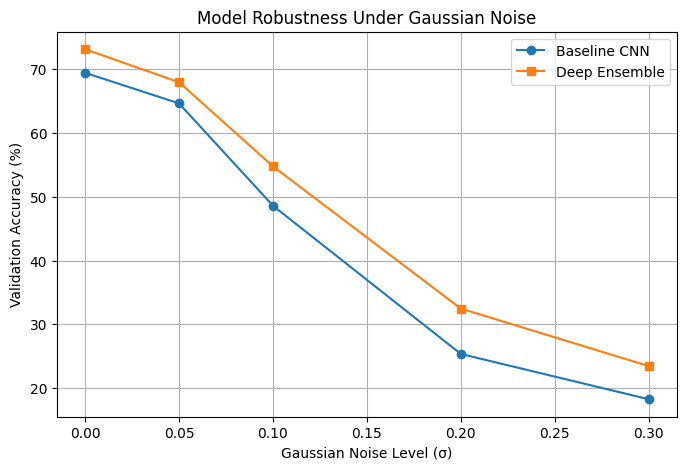

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    gaussian_results["Noise"],
    gaussian_results["Baseline Accuracy"],
    marker="o",
    label="Baseline CNN"
)

plt.plot(
    gaussian_results["Noise"],
    gaussian_results["Ensemble Accuracy"],
    marker="s",
    label="Deep Ensemble"
)

plt.xlabel("Gaussian Noise Level (σ)")
plt.ylabel("Validation Accuracy (%)")
plt.title("Model Robustness Under Gaussian Noise")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score

def uncertainty_under_corruption(
    baseline_model,
    ensemble_models,
    loader,
    noise_levels
):
    baseline_model.eval()

    for model in ensemble_models:
        model.eval()

    rows = []

    for sigma in noise_levels:

        baseline_probs_all = []
        ensemble_probs_all = []
        ensemble_individual_all = []
        labels_all = []

        # Reproducible noise for each noise level
        generator = torch.Generator(device="cpu")
        generator.manual_seed(2026 + int(sigma * 1000))

        with torch.no_grad():

            for images, labels in loader:

                noise = torch.randn(
                    images.shape,
                    generator=generator
                ) * sigma

                corrupted = torch.clamp(
                    images + noise,
                    0.0,
                    1.0
                ).to(device)

                # Baseline
                base_logits = baseline_model(corrupted)
                base_probs = F.softmax(base_logits, dim=1)

                # Individual ensemble predictions
                individual_probs = []

                for model in ensemble_models:
                    logits = model(corrupted)
                    probs = F.softmax(logits, dim=1)
                    individual_probs.append(probs)

                individual_probs = torch.stack(individual_probs)

                # Average ensemble probabilities
                ens_probs = individual_probs.mean(dim=0)

                baseline_probs_all.append(base_probs.cpu())
                ensemble_probs_all.append(ens_probs.cpu())
                ensemble_individual_all.append(
                    individual_probs.cpu()
                )
                labels_all.append(labels.cpu())

        base_probs = torch.cat(baseline_probs_all)
        ens_probs = torch.cat(ensemble_probs_all)
        individual_probs = torch.cat(
    ensemble_individual_all,
    dim=1
)
        labels = torch.cat(labels_all)

        # Predictions and errors
        base_errors = (
            base_probs.argmax(dim=1) != labels
        ).numpy()

        ens_errors = (
            ens_probs.argmax(dim=1) != labels
        ).numpy()

        base_accuracy = 100 * (1 - base_errors.mean())
        ens_accuracy = 100 * (1 - ens_errors.mean())

        # Baseline uncertainty
        base_uncertainty = (
            1 - base_probs.max(dim=1).values
        ).numpy()

        # Ensemble uncertainty
        ens_confidence_uncertainty = (
            1 - ens_probs.max(dim=1).values
        ).numpy()

        ens_entropy = -torch.sum(
            ens_probs * torch.log(ens_probs + 1e-10),
            dim=1
        )

        individual_entropy = -torch.sum(
            individual_probs *
            torch.log(individual_probs + 1e-10),
            dim=2
        )

        ens_mi = (
            ens_entropy - individual_entropy.mean(dim=0)
        ).clamp(min=0)

        # AUROC requires both correct and incorrect examples
        if len(np.unique(base_errors)) < 2:
            print(f"Skipping AUROC at noise {sigma}: only one error class")
            continue

        base_auc = roc_auc_score(
            base_errors,
            base_uncertainty
        )

        ens_conf_auc = roc_auc_score(
            ens_errors,
            ens_confidence_uncertainty
        )

        ens_entropy_auc = roc_auc_score(
            ens_errors,
            ens_entropy.numpy()
        )

        ens_mi_auc = roc_auc_score(
            ens_errors,
            ens_mi.numpy()
        )

        rows.append({
            "Noise": sigma,
            "Baseline Accuracy": base_accuracy,
            "Ensemble Accuracy": ens_accuracy,
            "Baseline Confidence AUROC": base_auc,
            "Ensemble Confidence AUROC": ens_conf_auc,
            "Ensemble Entropy AUROC": ens_entropy_auc,
            "Ensemble MI AUROC": ens_mi_auc
        })

        print(f"Noise level: {sigma:.2f}")
        print(f"Baseline AUROC: {base_auc:.4f}")
        print(f"Ensemble confidence AUROC: {ens_conf_auc:.4f}")
        print(f"Ensemble entropy AUROC: {ens_entropy_auc:.4f}")
        print(f"Ensemble mutual information AUROC: {ens_mi_auc:.4f}")
        print("-" * 45)

    return pd.DataFrame(rows)


uncertainty_corruption_results = uncertainty_under_corruption(
    model,
    ensemble_models,
    val_loader,
    NOISE_LEVELS
)

display(uncertainty_corruption_results.round(4))

Noise level: 0.00
Baseline AUROC: 0.8032
Ensemble confidence AUROC: 0.8168
Ensemble entropy AUROC: 0.7997
Ensemble mutual information AUROC: 0.7048
---------------------------------------------
Noise level: 0.05
Baseline AUROC: 0.7810
Ensemble confidence AUROC: 0.8071
Ensemble entropy AUROC: 0.7899
Ensemble mutual information AUROC: 0.6847
---------------------------------------------
Noise level: 0.10
Baseline AUROC: 0.6852
Ensemble confidence AUROC: 0.7310
Ensemble entropy AUROC: 0.7241
Ensemble mutual information AUROC: 0.6319
---------------------------------------------
Noise level: 0.20
Baseline AUROC: 0.6223
Ensemble confidence AUROC: 0.6422
Ensemble entropy AUROC: 0.6679
Ensemble mutual information AUROC: 0.6081
---------------------------------------------
Noise level: 0.30
Baseline AUROC: 0.6298
Ensemble confidence AUROC: 0.6408
Ensemble entropy AUROC: 0.6750
Ensemble mutual information AUROC: 0.6081
---------------------------------------------


,Noise,Baseline Accuracy,Ensemble Accuracy,Baseline Confidence AUROC,Ensemble Confidence AUROC,Ensemble Entropy AUROC,Ensemble MI AUROC
0,0.00,69.46,73.16,0.8032,0.8168,0.7997,0.7048
1,0.05,64.34,67.92,0.7810,0.8071,0.7899,0.6847
2,0.10,48.76,54.92,0.6852,0.7310,0.7241,0.6319
3,0.20,25.00,32.66,0.6223,0.6422,0.6679,0.6081
4,0.30,18.20,23.32,0.6298,0.6408,0.6750,0.6081


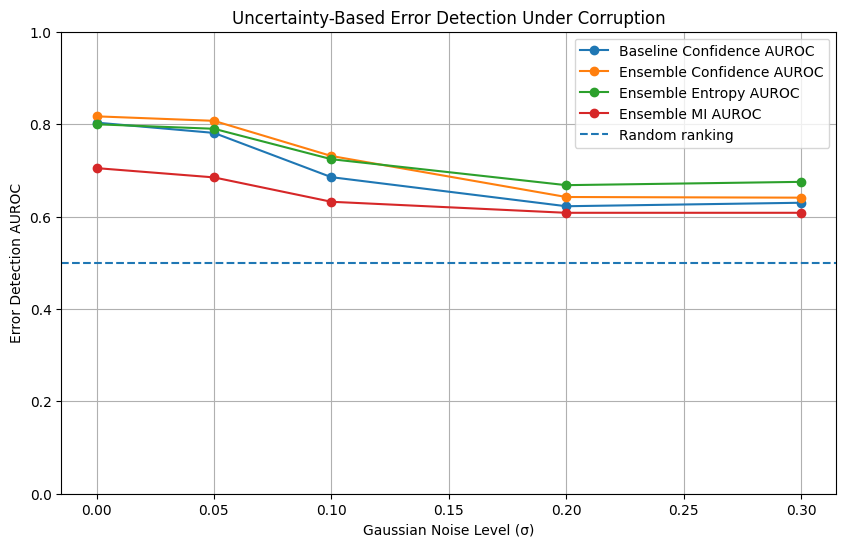

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

columns = [
    "Baseline Confidence AUROC",
    "Ensemble Confidence AUROC",
    "Ensemble Entropy AUROC",
    "Ensemble MI AUROC"
]

for column in columns:
    plt.plot(
        uncertainty_corruption_results["Noise"],
        uncertainty_corruption_results[column],
        marker="o",
        label=column
    )

plt.axhline(
    0.5,
    linestyle="--",
    label="Random ranking"
)

plt.xlabel("Gaussian Noise Level (σ)")
plt.ylabel("Error Detection AUROC")
plt.title("Uncertainty-Based Error Detection Under Corruption")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import torch
import torch.nn.functional as F
import pandas as pd
from sklearn.metrics import roc_auc_score

TEMPERATURE = 1.053596258
NOISE_LEVELS = [0.0, 0.05, 0.10, 0.20, 0.30]

def temperature_corruption_experiment(
    model,
    loader,
    noise_levels,
    temperature
):
    model.eval()
    results = []

    for sigma in noise_levels:

        all_logits = []
        all_labels = []

        generator = torch.Generator(device="cpu")
        generator.manual_seed(
            2026 + int(sigma * 1000)
        )

        with torch.no_grad():

            for images, labels in loader:

                noise = torch.randn(
                    images.shape,
                    generator=generator
                ) * sigma

                corrupted = torch.clamp(
                    images + noise,
                    0.0,
                    1.0
                ).to(device)

                logits = model(corrupted)

                all_logits.append(logits.cpu())
                all_labels.append(labels.cpu())

        logits = torch.cat(all_logits)
        labels = torch.cat(all_labels)

        # Original probabilities
        original_probs = F.softmax(logits, dim=1)

        # Temperature-scaled probabilities
        scaled_probs = F.softmax(
            logits / temperature,
            dim=1
        )

        # Metrics before calibration
        original_acc, original_ece, original_nll = (
            calculate_metrics(original_probs, labels)
        )

        # Metrics after calibration
        scaled_acc, scaled_ece, scaled_nll = (
            calculate_metrics(scaled_probs, labels)
        )

        # Error detection AUROC
        errors = (
            original_probs.argmax(dim=1) != labels
        ).numpy()

        original_uncertainty = (
            1 - original_probs.max(dim=1).values
        ).numpy()

        scaled_uncertainty = (
            1 - scaled_probs.max(dim=1).values
        ).numpy()

        original_auc = roc_auc_score(
            errors,
            original_uncertainty
        )

        scaled_auc = roc_auc_score(
            errors,
            scaled_uncertainty
        )

        results.append({
            "Noise": sigma,
            "Accuracy Before": original_acc,
            "Accuracy After": scaled_acc,
            "ECE Before": original_ece,
            "ECE After": scaled_ece,
            "NLL Before": original_nll,
            "NLL After": scaled_nll,
            "AUROC Before": original_auc,
            "AUROC After": scaled_auc
        })

        print(f"\nNoise level: {sigma:.2f}")
        print(f"ECE: {original_ece:.4f} -> {scaled_ece:.4f}")
        print(f"NLL: {original_nll:.4f} -> {scaled_nll:.4f}")
        print(f"AUROC: {original_auc:.4f} -> {scaled_auc:.4f}")

    return pd.DataFrame(results)


temperature_results = temperature_corruption_experiment(
    model,
    val_loader,
    NOISE_LEVELS,
    TEMPERATURE
)

print("\nTEMPERATURE SCALING UNDER CORRUPTION")
display(temperature_results.round(4))


Noise level: 0.00
ECE: 0.0102 -> 0.0111
NLL: 0.8706 -> 0.8683
AUROC: 0.8032 -> 0.8032

Noise level: 0.05
ECE: 0.0465 -> 0.0330
NLL: 1.0182 -> 1.0110
AUROC: 0.7810 -> 0.7811

Noise level: 0.10
ECE: 0.1972 -> 0.1833
NLL: 1.5873 -> 1.5518
AUROC: 0.6852 -> 0.6856

Noise level: 0.20
ECE: 0.5168 -> 0.5036
NLL: 3.1748 -> 3.0494
AUROC: 0.6223 -> 0.6235

Noise level: 0.30
ECE: 0.6379 -> 0.6259
NLL: 4.4855 -> 4.2859
AUROC: 0.6298 -> 0.6311

TEMPERATURE SCALING UNDER CORRUPTION


,Noise,Accuracy Before,Accuracy After,ECE Before,ECE After,NLL Before,NLL After,AUROC Before,AUROC After
0,0.00,69.46,69.46,0.0102,0.0111,0.8706,0.8683,0.8032,0.8032
1,0.05,64.34,64.34,0.0465,0.0330,1.0182,1.0110,0.7810,0.7811
2,0.10,48.76,48.76,0.1972,0.1833,1.5873,1.5518,0.6852,0.6856
3,0.20,25.00,25.00,0.5168,0.5036,3.1748,3.0494,0.6223,0.6235
4,0.30,18.20,18.20,0.6379,0.6259,4.4855,4.2859,0.6298,0.6311


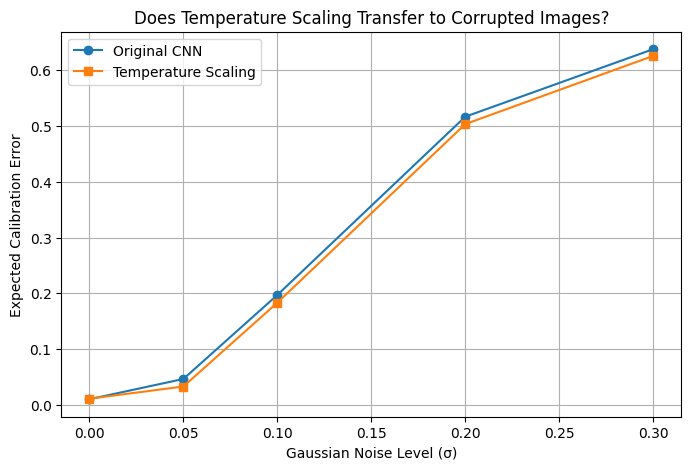

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    temperature_results["Noise"],
    temperature_results["ECE Before"],
    marker="o",
    label="Original CNN"
)

plt.plot(
    temperature_results["Noise"],
    temperature_results["ECE After"],
    marker="s",
    label="Temperature Scaling"
)

plt.xlabel("Gaussian Noise Level (σ)")
plt.ylabel("Expected Calibration Error")
plt.title("Does Temperature Scaling Transfer to Corrupted Images?")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
import pandas as pd

def selective_prediction(probs, labels, uncertainty_scores):

    # Convert tensors into NumPy arrays
    if isinstance(probs, torch.Tensor):
        probs = probs.cpu().numpy()

    if isinstance(labels, torch.Tensor):
        labels = labels.cpu().numpy()

    if isinstance(uncertainty_scores, torch.Tensor):
        uncertainty_scores = uncertainty_scores.cpu().numpy()

    # Get predicted classes
    predictions = np.argmax(probs, axis=1)

    # True means prediction is incorrect
    errors = predictions != labels

    # Lower uncertainty means more trustworthy
    sorted_indices = np.argsort(uncertainty_scores)

    coverage_levels = np.linspace(0.1, 1.0, 10)

    results = []

    for coverage in coverage_levels:

        # Number of samples to retain
        n_selected = max(1, int(len(labels) * coverage))

        # Keep the least uncertain predictions
        selected_indices = sorted_indices[:n_selected]

        # Calculate error rate among selected predictions
        selected_errors = errors[selected_indices]

        risk = selected_errors.mean()

        results.append({
            "Coverage": coverage,
            "Actual Coverage": n_selected / len(labels),
            "Risk": risk,
            "Accuracy": 1 - risk,
            "Selected Samples": n_selected
        })

    return pd.DataFrame(results)

In [ ]:
# Small example with 5 predictions

test_probs = torch.tensor([
    [0.90, 0.05, 0.05],
    [0.20, 0.70, 0.10],
    [0.40, 0.30, 0.30],
    [0.10, 0.20, 0.70],
    [0.45, 0.40, 0.15]
])

test_labels = torch.tensor([0, 1, 0, 1, 2])

test_uncertainty = torch.tensor([
    0.10, 0.30, 0.60, 0.40, 0.70
])

test_results = selective_prediction(
    test_probs,
    test_labels,
    test_uncertainty
)

display(test_results)

,Coverage,Actual Coverage,Risk,Accuracy,Selected Samples
0,0.1,0.2,0.000000,1.000000,1
1,0.2,0.2,0.000000,1.000000,1
2,0.3,0.2,0.000000,1.000000,1
3,0.4,0.4,0.000000,1.000000,2
4,0.5,0.4,0.000000,1.000000,2
5,0.6,0.6,0.333333,0.666667,3
6,0.7,0.6,0.333333,0.666667,3
7,0.8,0.8,0.250000,0.750000,4
8,0.9,0.8,0.250000,0.750000,4
9,1.0,1.0,0.400000,0.600000,5


In [ ]:
model.eval()

for m in ensemble_models:
    m.eval()

baseline_probs_list = []
ensemble_probs_list = []
individual_probs_list = []
validation_labels_list = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        # Baseline CNN predictions
        baseline_logits = model(images)

        baseline_probs = F.softmax(
            baseline_logits, dim=1
        )

        # Deep Ensemble predictions
        individual_batch = []

        for m in ensemble_models:
            logits = m(images)
            individual_batch.append(
                F.softmax(logits, dim=1)
            )

        individual_batch = torch.stack(individual_batch)

        ensemble_batch = individual_batch.mean(dim=0)

        baseline_probs_list.append(baseline_probs.cpu())
        ensemble_probs_list.append(ensemble_batch.cpu())
        individual_probs_list.append(individual_batch.cpu())
        validation_labels_list.append(labels.cpu())

# Combine all batches
baseline_val_probs = torch.cat(baseline_probs_list)
ensemble_val_probs = torch.cat(ensemble_probs_list)

ensemble_individual_val_probs = torch.cat(
    individual_probs_list, dim=1
)

validation_labels = torch.cat(validation_labels_list)

print("Baseline probabilities:", baseline_val_probs.shape)
print("Ensemble probabilities:", ensemble_val_probs.shape)
print("Individual ensemble predictions:", ensemble_individual_val_probs.shape)
print("Validation labels:", validation_labels.shape)

Baseline probabilities: torch.Size([5000, 10])
Ensemble probabilities: torch.Size([5000, 10])
Individual ensemble predictions: torch.Size([3, 5000, 10])
Validation labels: torch.Size([5000])


In [ ]:
# 1. Baseline uncertainty
baseline_uncertainty = (
    1 - baseline_val_probs.max(dim=1).values
)

# 2. Ensemble confidence uncertainty
ensemble_confidence_uncertainty = (
    1 - ensemble_val_probs.max(dim=1).values
)

# 3. Ensemble predictive entropy
ensemble_entropy = -torch.sum(
    ensemble_val_probs *
    torch.log(ensemble_val_probs + 1e-10),
    dim=1
)

# 4. Ensemble mutual information
individual_entropy = -torch.sum(
    ensemble_individual_val_probs *
    torch.log(ensemble_individual_val_probs + 1e-10),
    dim=2
)

ensemble_mutual_information = (
    ensemble_entropy -
    individual_entropy.mean(dim=0)
).clamp(min=0)

print("Uncertainty scores generated!")

print("Baseline:", baseline_uncertainty.shape)
print("Ensemble confidence:", ensemble_confidence_uncertainty.shape)
print("Predictive entropy:", ensemble_entropy.shape)
print("Mutual information:", ensemble_mutual_information.shape)

Uncertainty scores generated!
Baseline: torch.Size([5000])
Ensemble confidence: torch.Size([5000])
Predictive entropy: torch.Size([5000])
Mutual information: torch.Size([5000])


In [ ]:
# Calculate selective prediction curves

baseline_selective = selective_prediction(
    baseline_val_probs,
    validation_labels,
    baseline_uncertainty
)

ensemble_conf_selective = selective_prediction(
    ensemble_val_probs,
    validation_labels,
    ensemble_confidence_uncertainty
)

ensemble_entropy_selective = selective_prediction(
    ensemble_val_probs,
    validation_labels,
    ensemble_entropy
)

ensemble_mi_selective = selective_prediction(
    ensemble_val_probs,
    validation_labels,
    ensemble_mutual_information
)

# Combine results
coverage_risk_results = pd.DataFrame({
    "Coverage": baseline_selective["Actual Coverage"],
    "Baseline CNN": baseline_selective["Risk"],
    "Ensemble Confidence": ensemble_conf_selective["Risk"],
    "Ensemble Entropy": ensemble_entropy_selective["Risk"],
    "Ensemble Mutual Information": ensemble_mi_selective["Risk"]
})

display(coverage_risk_results.round(4))

,Coverage,Baseline CNN,Ensemble Confidence,Ensemble Entropy,Ensemble Mutual Information
0,0.1,0.0080,0.0040,0.0040,0.0100
1,0.2,0.0250,0.0080,0.0080,0.0430
2,0.3,0.0480,0.0227,0.0247,0.0787
3,0.4,0.0775,0.0480,0.0595,0.1185
4,0.5,0.1108,0.0788,0.0924,0.1476
5,0.6,0.1457,0.1100,0.1217,0.1783
6,0.7,0.1849,0.1543,0.1569,0.2046
7,0.8,0.2240,0.1862,0.1930,0.2280
8,0.9,0.2618,0.2247,0.2289,0.2487
9,1.0,0.3054,0.2684,0.2684,0.2684


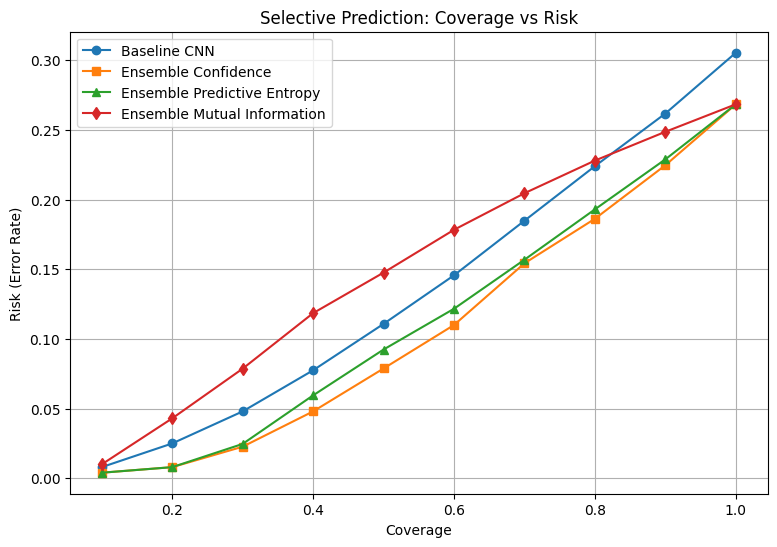

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.plot(
    coverage_risk_results["Coverage"],
    coverage_risk_results["Baseline CNN"],
    marker="o",
    label="Baseline CNN"
)

plt.plot(
    coverage_risk_results["Coverage"],
    coverage_risk_results["Ensemble Confidence"],
    marker="s",
    label="Ensemble Confidence"
)

plt.plot(
    coverage_risk_results["Coverage"],
    coverage_risk_results["Ensemble Entropy"],
    marker="^",
    label="Ensemble Predictive Entropy"
)

plt.plot(
    coverage_risk_results["Coverage"],
    coverage_risk_results["Ensemble Mutual Information"],
    marker="d",
    label="Ensemble Mutual Information"
)

plt.xlabel("Coverage")
plt.ylabel("Risk (Error Rate)")
plt.title("Selective Prediction: Coverage vs Risk")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import torch
import torch.nn.functional as F
import numpy as np

noise_levels = [0.00, 0.05, 0.10, 0.20, 0.30]

def get_corrupted_validation_probs(sigma, seed=2026):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model.eval()
    for net in ensemble_models:
        net.eval()

    baseline_probs_all = []
    ensemble_probs_all = []
    individual_probs_all = []
    labels_all = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            # Create one corrupted batch shared by every model
            noisy_images = (
                images + sigma * torch.randn_like(images)
            ).clamp(0, 1)

            # Baseline predictions
            baseline_probs = F.softmax(
                model(noisy_images), dim=1
            )

            # Individual ensemble predictions
            individual_probs = torch.stack([
                F.softmax(net(noisy_images), dim=1)
                for net in ensemble_models
            ], dim=1)

            # Average ensemble prediction
            ensemble_probs = individual_probs.mean(dim=1)

            baseline_probs_all.append(baseline_probs.cpu())
            ensemble_probs_all.append(ensemble_probs.cpu())
            individual_probs_all.append(individual_probs.cpu())
            labels_all.append(labels.cpu())

    return {
        "baseline": torch.cat(baseline_probs_all),
        "ensemble": torch.cat(ensemble_probs_all),
        "individual": torch.cat(individual_probs_all, dim=0).permute(1, 0, 2),
        "labels": torch.cat(labels_all)
    }


corrupted_validation = {}

for sigma in noise_levels:
    corrupted_validation[sigma] = get_corrupted_validation_probs(sigma)
    print(
        f"Noise {sigma:.2f}: "
        f"Baseline {corrupted_validation[sigma]['baseline'].shape}, "
        f"Ensemble {corrupted_validation[sigma]['ensemble'].shape}"
    )

Noise 0.00: Baseline torch.Size([5000, 10]), Ensemble torch.Size([5000, 10])
Noise 0.05: Baseline torch.Size([5000, 10]), Ensemble torch.Size([5000, 10])
Noise 0.10: Baseline torch.Size([5000, 10]), Ensemble torch.Size([5000, 10])
Noise 0.20: Baseline torch.Size([5000, 10]), Ensemble torch.Size([5000, 10])
Noise 0.30: Baseline torch.Size([5000, 10]), Ensemble torch.Size([5000, 10])


In [ ]:
corrupted_uncertainties = {}

for sigma in noise_levels:
    data = corrupted_validation[sigma]

    baseline_probs = data["baseline"]
    ensemble_probs = data["ensemble"]
    individual_probs = data["individual"]

    # Confidence-based uncertainty
    baseline_uncertainty = 1 - baseline_probs.max(dim=1).values
    ensemble_confidence_uncertainty = 1 - ensemble_probs.max(dim=1).values

    # Predictive entropy
    ensemble_entropy = -(
        ensemble_probs * torch.log(ensemble_probs + 1e-10)
    ).sum(dim=1)

    # Entropy of each individual model
    individual_entropy = -(
        individual_probs * torch.log(individual_probs + 1e-10)
    ).sum(dim=2)

    # Mutual information = predictive entropy - expected entropy
    ensemble_mi = (
        ensemble_entropy - individual_entropy.mean(dim=0)
    ).clamp(min=0)

    corrupted_uncertainties[sigma] = {
        "baseline_confidence": baseline_uncertainty,
        "ensemble_confidence": ensemble_confidence_uncertainty,
        "ensemble_entropy": ensemble_entropy,
        "ensemble_mi": ensemble_mi
    }

    print(
        f"Noise {sigma:.2f}: "
        f"Baseline {baseline_uncertainty.shape}, "
        f"Ensemble MI {ensemble_mi.shape}"
    )

Noise 0.00: Baseline torch.Size([5000]), Ensemble MI torch.Size([5000])
Noise 0.05: Baseline torch.Size([5000]), Ensemble MI torch.Size([5000])
Noise 0.10: Baseline torch.Size([5000]), Ensemble MI torch.Size([5000])
Noise 0.20: Baseline torch.Size([5000]), Ensemble MI torch.Size([5000])
Noise 0.30: Baseline torch.Size([5000]), Ensemble MI torch.Size([5000])


In [ ]:
corrupted_selective_results = {}

for sigma in noise_levels:
    data = corrupted_validation[sigma]
    uncertainty = corrupted_uncertainties[sigma]
    labels = data["labels"]

    # Calculate selective prediction for all four methods
    baseline_result = selective_prediction(
        data["baseline"],
        labels,
        uncertainty["baseline_confidence"]
    )

    ensemble_conf_result = selective_prediction(
        data["ensemble"],
        labels,
        uncertainty["ensemble_confidence"]
    )

    ensemble_entropy_result = selective_prediction(
        data["ensemble"],
        labels,
        uncertainty["ensemble_entropy"]
    )

    ensemble_mi_result = selective_prediction(
        data["ensemble"],
        labels,
        uncertainty["ensemble_mi"]
    )

    # Combine risk values into one table
    results = pd.DataFrame({
        "Coverage": baseline_result["Actual Coverage"],
        "Baseline CNN": baseline_result["Risk"],
        "Ensemble Confidence": ensemble_conf_result["Risk"],
        "Ensemble Entropy": ensemble_entropy_result["Risk"],
        "Ensemble Mutual Information": ensemble_mi_result["Risk"]
    })

    corrupted_selective_results[sigma] = results

    print(f"\n===== Noise Level: {sigma:.2f} =====")
    display(results.round(4))


===== Noise Level: 0.00 =====


,Coverage,Baseline CNN,Ensemble Confidence,Ensemble Entropy,Ensemble Mutual Information
0,0.1,0.0080,0.0040,0.0040,0.0100
1,0.2,0.0250,0.0080,0.0080,0.0430
2,0.3,0.0480,0.0227,0.0247,0.0787
3,0.4,0.0775,0.0480,0.0595,0.1185
4,0.5,0.1108,0.0788,0.0924,0.1476
5,0.6,0.1457,0.1100,0.1217,0.1783
6,0.7,0.1849,0.1543,0.1569,0.2046
7,0.8,0.2240,0.1862,0.1930,0.2280
8,0.9,0.2618,0.2247,0.2289,0.2487
9,1.0,0.3054,0.2684,0.2684,0.2684



===== Noise Level: 0.05 =====


,Coverage,Baseline CNN,Ensemble Confidence,Ensemble Entropy,Ensemble Mutual Information
0,0.1,0.0200,0.0100,0.0120,0.0260
1,0.2,0.0440,0.0190,0.0210,0.0840
2,0.3,0.0800,0.0433,0.0487,0.1347
3,0.4,0.1170,0.0780,0.0885,0.1675
4,0.5,0.1516,0.1148,0.1304,0.1984
5,0.6,0.2027,0.1540,0.1700,0.2333
6,0.7,0.2451,0.1943,0.2029,0.2591
7,0.8,0.2790,0.2370,0.2425,0.2802
8,0.9,0.3169,0.2791,0.2807,0.2991
9,1.0,0.3546,0.3198,0.3198,0.3198



===== Noise Level: 0.10 =====


,Coverage,Baseline CNN,Ensemble Confidence,Ensemble Entropy,Ensemble Mutual Information
0,0.1,0.1260,0.0520,0.0400,0.1200
1,0.2,0.2260,0.1290,0.1180,0.2220
2,0.3,0.2920,0.1940,0.1927,0.2887
3,0.4,0.3400,0.2520,0.2510,0.3325
4,0.5,0.3848,0.2928,0.2912,0.3648
5,0.6,0.4140,0.3287,0.3273,0.3930
6,0.7,0.4429,0.3586,0.3597,0.4126
7,0.8,0.4668,0.3882,0.3905,0.4292
8,0.9,0.4909,0.4196,0.4204,0.4409
9,1.0,0.5134,0.4518,0.4518,0.4518



===== Noise Level: 0.20 =====


,Coverage,Baseline CNN,Ensemble Confidence,Ensemble Entropy,Ensemble Mutual Information
0,0.1,0.4420,0.3120,0.3020,0.3760
1,0.2,0.5580,0.4560,0.4460,0.5070
2,0.3,0.6273,0.5300,0.5033,0.5687
3,0.4,0.6740,0.5710,0.5450,0.6045
4,0.5,0.6996,0.5996,0.5808,0.6260
5,0.6,0.7180,0.6220,0.6063,0.6413
6,0.7,0.7289,0.6346,0.6300,0.6500
7,0.8,0.7378,0.6538,0.6485,0.6617
8,0.9,0.7433,0.6642,0.6642,0.6724
9,1.0,0.7506,0.6798,0.6798,0.6798



===== Noise Level: 0.30 =====


,Coverage,Baseline CNN,Ensemble Confidence,Ensemble Entropy,Ensemble Mutual Information
0,0.1,0.5840,0.5380,0.5360,0.5700
1,0.2,0.6690,0.6250,0.6080,0.6680
2,0.3,0.7207,0.6533,0.6367,0.6793
3,0.4,0.7505,0.6800,0.6455,0.7025
4,0.5,0.7680,0.6988,0.6704,0.7232
5,0.6,0.7837,0.7140,0.6950,0.7327
6,0.7,0.7997,0.7274,0.7157,0.7420
7,0.8,0.8068,0.7438,0.7378,0.7500
8,0.9,0.8153,0.7576,0.7551,0.7591
9,1.0,0.8204,0.7664,0.7664,0.7664


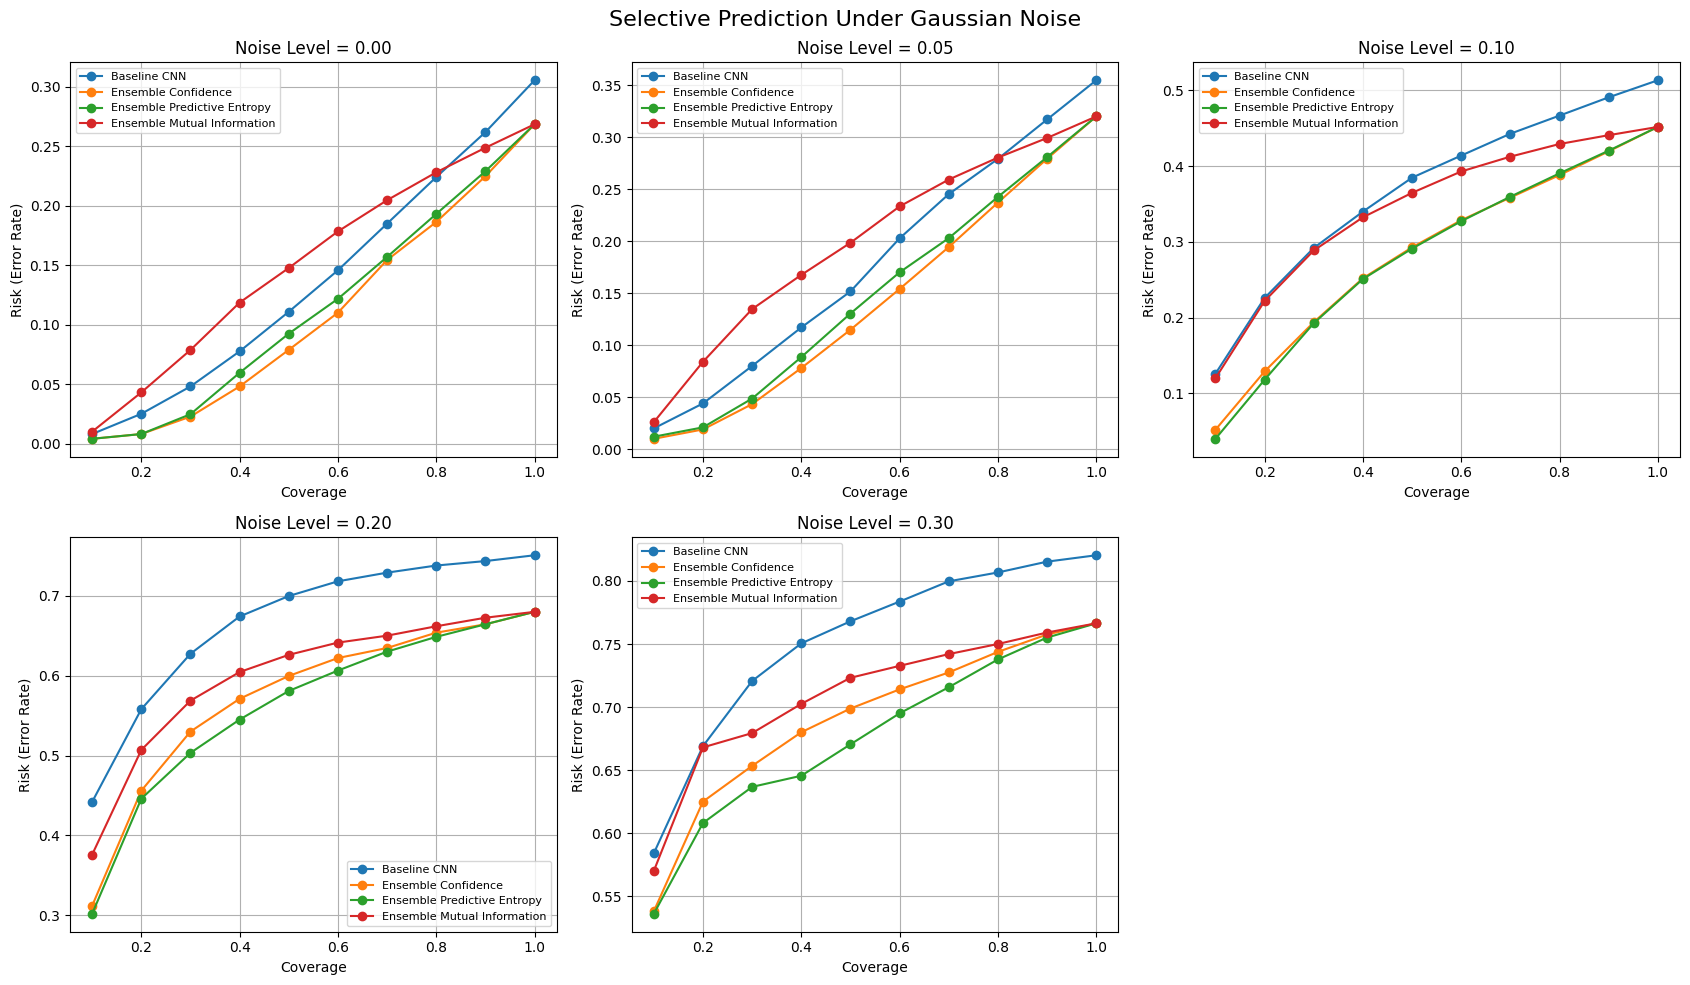

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

methods = [
    ("Baseline CNN", "Baseline CNN"),
    ("Ensemble Confidence", "Ensemble Confidence"),
    ("Ensemble Entropy", "Ensemble Predictive Entropy"),
    ("Ensemble Mutual Information", "Ensemble Mutual Information")
]

for i, sigma in enumerate(noise_levels):
    ax = axes[i]
    results = corrupted_selective_results[sigma]

    for column, label in methods:
        ax.plot(
            results["Coverage"],
            results[column],
            marker="o",
            label=label
        )

    ax.set_title(f"Noise Level = {sigma:.2f}")
    ax.set_xlabel("Coverage")
    ax.set_ylabel("Risk (Error Rate)")
    ax.grid(True)
    ax.legend(fontsize=8)

# Hide the unused sixth subplot
axes[5].axis("off")

plt.suptitle(
    "Selective Prediction Under Gaussian Noise",
    fontsize=16
)
plt.tight_layout()
plt.show()

In [ ]:
repeated_selective_results = {}

seeds = [2026, 2027, 2028, 2029, 2030]

for seed in seeds:
    for sigma in noise_levels:

        data = get_corrupted_validation_probs(sigma, seed=seed)

        baseline_probs = data["baseline"]
        ensemble_probs = data["ensemble"]
        individual_probs = data["individual"]
        labels = data["labels"]

        baseline_unc = 1 - baseline_probs.max(dim=1).values
        ensemble_conf_unc = 1 - ensemble_probs.max(dim=1).values

        ensemble_entropy = -(
            ensemble_probs * torch.log(ensemble_probs + 1e-10)
        ).sum(dim=1)

        individual_entropy = -(
            individual_probs * torch.log(individual_probs + 1e-10)
        ).sum(dim=2)

        ensemble_mi = (
            ensemble_entropy - individual_entropy.mean(dim=0)
        ).clamp(min=0)

        results = {
            "Baseline CNN": selective_prediction(
                baseline_probs, labels, baseline_unc
            ),
            "Ensemble Confidence": selective_prediction(
                ensemble_probs, labels, ensemble_conf_unc
            ),
            "Ensemble Entropy": selective_prediction(
                ensemble_probs, labels, ensemble_entropy
            ),
            "Ensemble Mutual Information": selective_prediction(
                ensemble_probs, labels, ensemble_mi
            )
        }

        repeated_selective_results[(seed, sigma)] = results

    print(f"Completed seed {seed}")

print("\nAll repeated experiments completed.")

Completed seed 2026
Completed seed 2027
Completed seed 2028
Completed seed 2029
Completed seed 2030

All repeated experiments completed.


In [ ]:
import pandas as pd
import numpy as np

methods = [
    "Baseline CNN",
    "Ensemble Confidence",
    "Ensemble Entropy",
    "Ensemble Mutual Information"
]

summary_records = []

for sigma in noise_levels:
    for method in methods:

        seed_risks = []

        for seed in seeds:
            result = repeated_selective_results[(seed, sigma)][method]
            seed_risks.append(result["Risk"].to_numpy())

        seed_risks = np.array(seed_risks)

        mean_risk = seed_risks.mean(axis=0)
        std_risk = seed_risks.std(axis=0, ddof=1)

        for i, coverage in enumerate(
            repeated_selective_results[(seeds[0], sigma)][method]["Actual Coverage"]
        ):
            summary_records.append({
                "Noise": sigma,
                "Method": method,
                "Coverage": coverage,
                "Mean Risk": mean_risk[i],
                "Std Risk": std_risk[i]
            })

repeated_summary = pd.DataFrame(summary_records)

print("Repeated experiment summary (mean ± standard deviation):")
display(repeated_summary.round(4))

Repeated experiment summary (mean ± standard deviation):


,Noise,Method,Coverage,Mean Risk,Std Risk
0,0.0,Baseline CNN,0.1,0.0080,0.0000
1,0.0,Baseline CNN,0.2,0.0250,0.0000
2,0.0,Baseline CNN,0.3,0.0480,0.0000
3,0.0,Baseline CNN,0.4,0.0775,0.0000
4,0.0,Baseline CNN,0.5,0.1108,0.0000
...,...,...,...,...,...
195,0.3,Ensemble Mutual Information,0.6,0.7279,0.0067
196,0.3,Ensemble Mutual Information,0.7,0.7391,0.0062
197,0.3,Ensemble Mutual Information,0.8,0.7485,0.0053
198,0.3,Ensemble Mutual Information,0.9,0.7579,0.0035


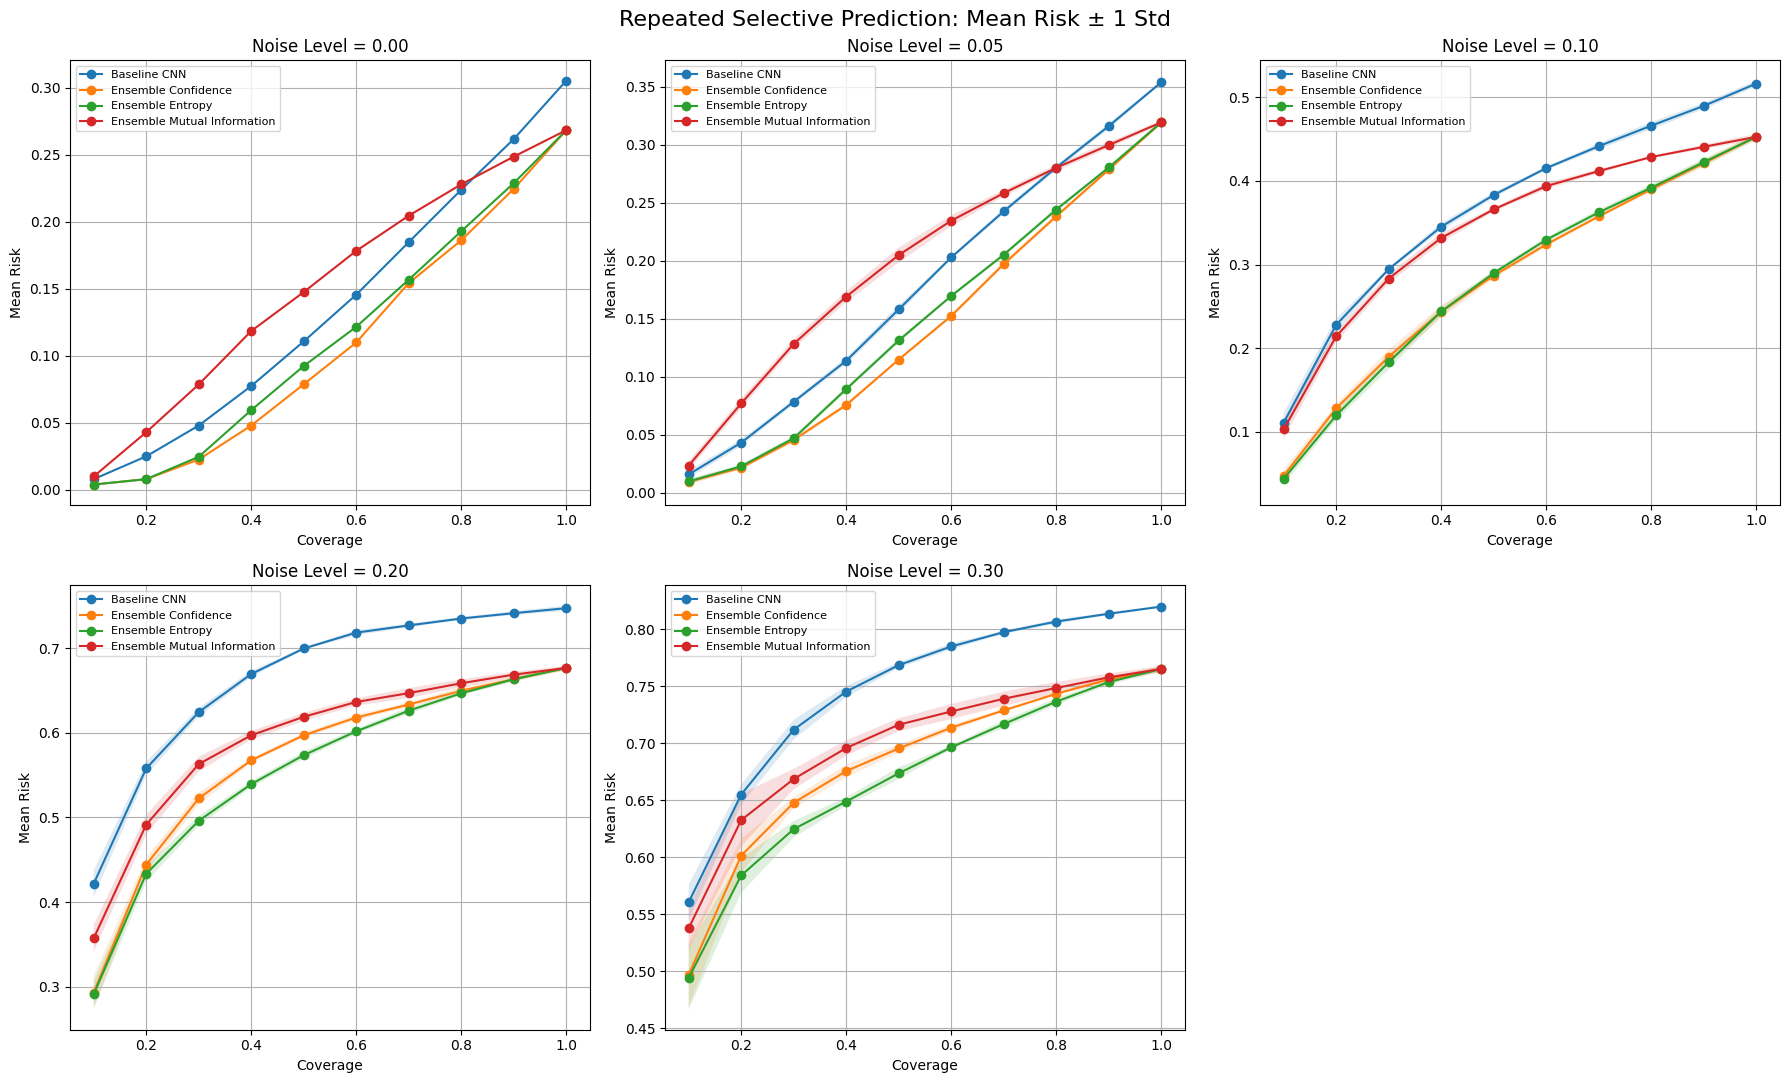

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for i, sigma in enumerate(noise_levels):
    ax = axes[i]

    for method in methods:
        subset = repeated_summary[
            (repeated_summary["Noise"] == sigma) &
            (repeated_summary["Method"] == method)
        ].sort_values("Coverage")

        coverage = subset["Coverage"].to_numpy()
        mean = subset["Mean Risk"].to_numpy()
        std = subset["Std Risk"].to_numpy()

        ax.plot(
            coverage, mean,
            marker="o",
            label=method
        )

        ax.fill_between(
            coverage,
            np.maximum(0, mean - std),
            np.minimum(1, mean + std),
            alpha=0.15
        )

    ax.set_title(f"Noise Level = {sigma:.2f}")
    ax.set_xlabel("Coverage")
    ax.set_ylabel("Mean Risk")
    ax.grid(True)
    ax.legend(fontsize=8)

axes[5].axis("off")

plt.suptitle(
    "Repeated Selective Prediction: Mean Risk ± 1 Std",
    fontsize=16
)
plt.tight_layout()
plt.show()

In [ ]:
# Extract results at 50% coverage
summary_50 = repeated_summary[
    np.isclose(repeated_summary["Coverage"], 0.5)
].copy()

# Mean risk table
mean_table = summary_50.pivot(
    index="Noise",
    columns="Method",
    values="Mean Risk"
)

# Standard deviation table
std_table = summary_50.pivot(
    index="Noise",
    columns="Method",
    values="Std Risk"
)

print("MEAN SELECTIVE RISK AT 50% COVERAGE")
display(mean_table.round(4))

print("STANDARD DEVIATION AT 50% COVERAGE")
display(std_table.round(4))

# Relative risk reduction compared with baseline
improvement_table = (
    mean_table["Baseline CNN"].values.reshape(-1, 1)
    - mean_table[
        ["Ensemble Confidence", "Ensemble Entropy",
         "Ensemble Mutual Information"]
    ].values
) / mean_table["Baseline CNN"].values.reshape(-1, 1) * 100

improvement_table = pd.DataFrame(
    improvement_table,
    index=mean_table.index,
    columns=[
        "Confidence improvement (%)",
        "Entropy improvement (%)",
        "Mutual Information improvement (%)"
    ]
)

print("RELATIVE RISK REDUCTION VS BASELINE")
display(improvement_table.round(2))

MEAN SELECTIVE RISK AT 50% COVERAGE


Method,Baseline CNN,Ensemble Confidence,Ensemble Entropy,Ensemble Mutual Information
Noise,,,,
0.00,0.1108,0.0788,0.0924,0.1476
0.05,0.1579,0.1146,0.1311,0.2047
0.10,0.3832,0.2866,0.2898,0.3660
0.20,0.6994,0.5970,0.5735,0.6188
0.30,0.7686,0.6955,0.6737,0.7163


STANDARD DEVIATION AT 50% COVERAGE


Method,Baseline CNN,Ensemble Confidence,Ensemble Entropy,Ensemble Mutual Information
Noise,,,,
0.00,0.0000,0.0000,0.0000,0.0000
0.05,0.0036,0.0009,0.0020,0.0063
0.10,0.0033,0.0039,0.0030,0.0025
0.20,0.0015,0.0030,0.0044,0.0047
0.30,0.0025,0.0034,0.0052,0.0057


RELATIVE RISK REDUCTION VS BASELINE


,Confidence improvement (%),Entropy improvement (%),Mutual Information improvement (%)
Noise,,,
0.00,28.88,16.61,-33.21
0.05,27.41,16.97,-29.64
0.10,25.20,24.38,4.49
0.20,14.64,18.00,11.53
0.30,9.51,12.35,6.81


In [ ]:
aurc_records = []

for sigma in noise_levels:
    for method in methods:

        subset = repeated_summary[
            (repeated_summary["Noise"] == sigma) &
            (repeated_summary["Method"] == method)
        ].sort_values("Coverage")

        coverage = subset["Coverage"].to_numpy()
        mean_risk = subset["Mean Risk"].to_numpy()

        # Calculate normalized area under risk-coverage curve
        aurc = np.trapezoid(mean_risk, x=coverage) / (
            coverage[-1] - coverage[0]
        )

        aurc_records.append({
            "Noise": sigma,
            "Method": method,
            "AURC": aurc
        })

aurc_table = pd.DataFrame(aurc_records)

aurc_pivot = aurc_table.pivot(
    index="Noise",
    columns="Method",
    values="AURC"
)

print("AURC COMPARISON — LOWER IS BETTER")
display(aurc_pivot.round(4))

AURC COMPARISON — LOWER IS BETTER


Method,Baseline CNN,Ensemble Confidence,Ensemble Entropy,Ensemble Mutual Information
Noise,,,,
0.00,0.1371,0.1077,0.1135,0.1541
0.05,0.1799,0.1430,0.1503,0.2024
0.10,0.3752,0.2878,0.2879,0.3498
0.20,0.6729,0.5755,0.5626,0.5997
0.30,0.7527,0.6882,0.6738,0.7043


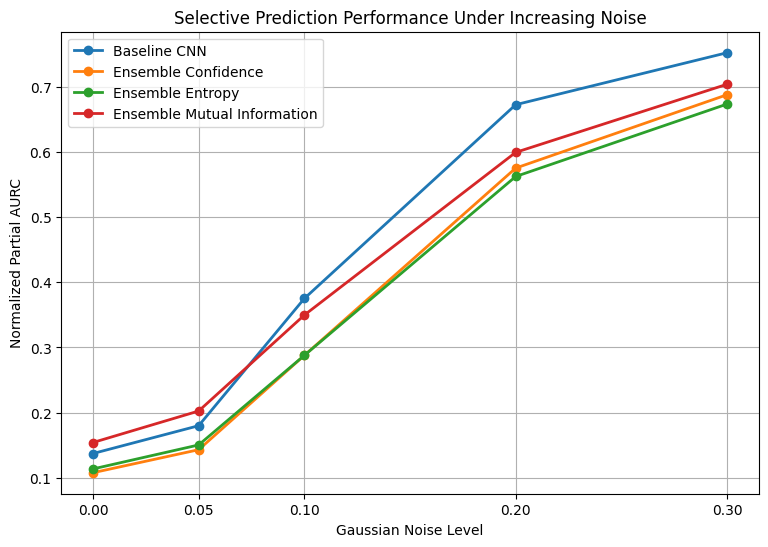

In [ ]:
plt.figure(figsize=(9, 6))

for method in methods:
    subset = aurc_table[
        aurc_table["Method"] == method
    ].sort_values("Noise")

    plt.plot(
        subset["Noise"],
        subset["AURC"],
        marker="o",
        linewidth=2,
        label=method
    )

plt.xlabel("Gaussian Noise Level")
plt.ylabel("Normalized Partial AURC")
plt.title("Selective Prediction Performance Under Increasing Noise")
plt.xticks(noise_levels)
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
# Export the main research results

repeated_summary.to_csv(
    "repeated_selective_prediction_results.csv",
    index=False
)

aurc_table.to_csv(
    "selective_prediction_aurc_results.csv",
    index=False
)

print("Research result files saved successfully.")

from google.colab import files

files.download("repeated_selective_prediction_results.csv")
files.download("selective_prediction_aurc_results.csv")

Research result files saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Please upload selective_prediction_aurc_results.csv


Saving selective_prediction_aurc_results.csv to selective_prediction_aurc_results.csv


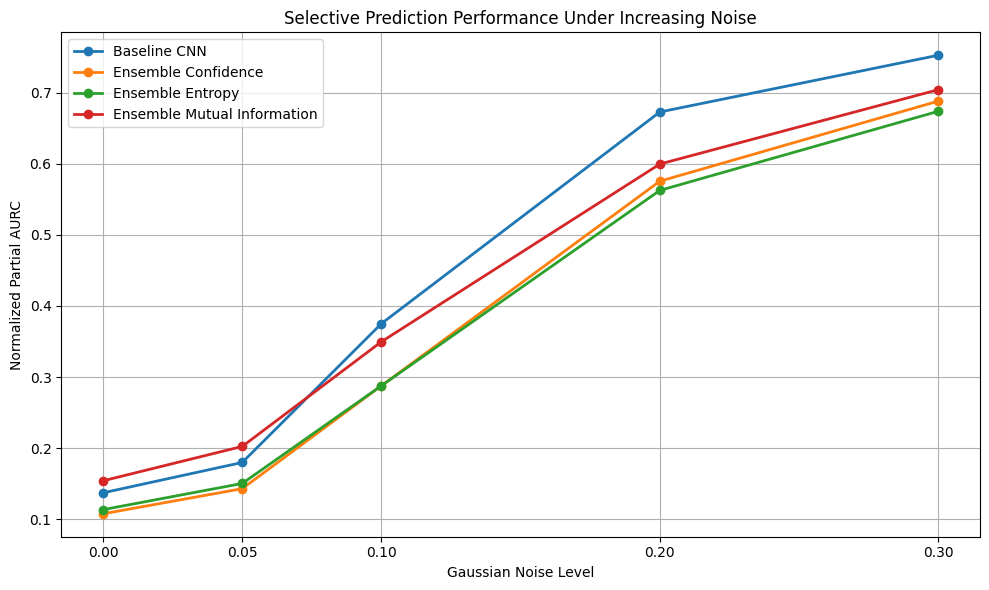

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

AURC graph saved successfully!


In [ ]:

# STEP: Recreate and save the AURC graph

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

from google.colab import files

# 1. Define the methods
methods = [
    "Baseline CNN",
    "Ensemble Confidence",
    "Ensemble Entropy",
    "Ensemble Mutual Information"
]

# 2. Load AURC results if not already available
if "aurc_table" not in globals():
    filename = "selective_prediction_aurc_results.csv"

    if os.path.exists(filename):
        aurc_table = pd.read_csv(filename)
    else:
        print("Please upload selective_prediction_aurc_results.csv")
        uploaded = files.upload()
        aurc_table = pd.read_csv(filename)

# 3. Create the graph
plt.figure(figsize=(10, 6))

for method in methods:
    subset = aurc_table[
        aurc_table["Method"] == method
    ].sort_values("Noise")

    plt.plot(
        subset["Noise"],
        subset["AURC"],
        marker="o",
        linewidth=2,
        label=method
    )

plt.xlabel("Gaussian Noise Level")
plt.ylabel("Normalized Partial AURC")
plt.title("Selective Prediction Performance Under Increasing Noise")
plt.xticks([0.00, 0.05, 0.10, 0.20, 0.30])
plt.grid(True)
plt.legend()
plt.tight_layout()

# 4. Save the graph
plt.savefig(
    "selective_prediction_aurc.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Download the image
files.download("selective_prediction_aurc.png")

print("AURC graph saved successfully!")

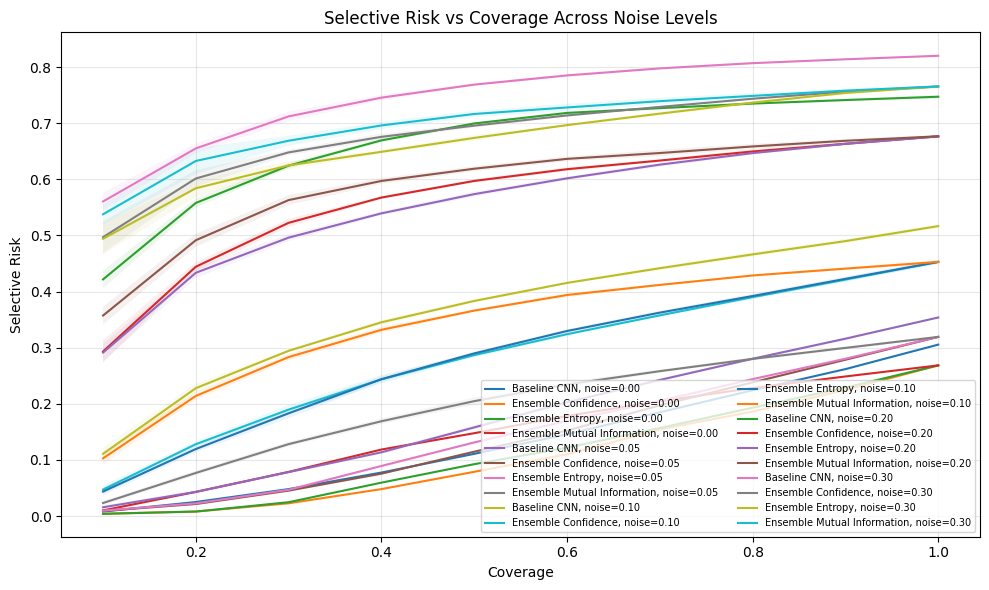

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Graph saved successfully!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
import os

filename = "repeated_selective_prediction_results.csv"

if not os.path.exists(filename):
    uploaded = files.upload()
    filename = next(iter(uploaded))

repeated_summary = pd.read_csv(filename)

plt.figure(figsize=(10, 6))

# Separate graph lines for each noise level and method
for noise in sorted(repeated_summary["Noise"].unique()):
    for method in repeated_summary["Method"].unique():

        data = repeated_summary[
            (repeated_summary["Noise"] == noise) &
            (repeated_summary["Method"] == method)
        ].sort_values("Coverage")

        coverage = data["Coverage"].to_numpy()
        mean = data["Mean Risk"].to_numpy()
        std = data["Std Risk"].to_numpy()

        plt.plot(
            coverage,
            mean,
            label=f"{method}, noise={noise:.2f}"
        )

        plt.fill_between(
            coverage,
            mean - std,
            mean + std,
            alpha=0.08
        )

plt.xlabel("Coverage")
plt.ylabel("Selective Risk")
plt.title("Selective Risk vs Coverage Across Noise Levels")
plt.legend(fontsize=7, ncol=2)
plt.grid(alpha=0.3)
plt.tight_layout()

output_file = "selective_risk_coverage.png"
plt.savefig(output_file, dpi=300, bbox_inches="tight")
plt.show()

files.download(output_file)

print("Graph saved successfully!")